# Company A — Churn-Risk Targeting PoC
**GCI World 2026 · Final Assignment · Shafayet Jamil**

Reproducible analysis behind the slide deck. Run top-to-bottom (≈25 min on a 4-core laptop CPU, roughly twice that on a free 2-core Colab runtime — the 5-fold cross-validation of all candidate models dominates).

| # | Section | Question it answers |
|---|---|---|
| 1 | Market context | Why does churn matter for a mature mobile operator? |
| 2 | Setup & data loading | What do we have? |
| 3 | Data quality | What must be cleaned? Any leakage? |
| 4 | EDA | Which customer signals separate churners from stayers? |
| 5 | Problem definition | What exactly do we predict, and how do we score it? |
| 6 | Feature engineering | Which derived signals capture *behaviour change*? |
| 7 | Modelling | Which model ranks churn risk best — and what made it more accurate? |
| 8 | Evaluation & interpretation | How good is it, and *why* does it predict churn? |
| 9 | Business proposal | Who to target, with what, and what is it worth? |
| 10 | Risks & next steps | |
| 11 | References | |

### Executive summary
- **Problem:** Company A loses customers to competitors in a saturated market, but has no way to decide *whom* to retain or *with what*. Retention budgets spent blindly are wasted on customers who would have stayed anyway.
- **What drives churn (EDA + model):** (1) **falling usage** — above all a sudden drop in the latest month relative to the customer's previous three months; (2) **ageing handsets** — churn jumps from ~40% to ~55–60% once a handset passes ~1 year; (3) the **contract-end window** at ~11–12 months tenure (churn 62–65%); (4) **low-commitment plans** (low recurring charge, cheap handsets). Network quality is *not* a main driver.
- **Model:** a **soft-voting ensemble of three tuned gradient-boosting models (LightGBM + CatBoost + XGBoost)**, selected over Logistic Regression, Random Forest and each single model by 5-fold cross-validation. **Test ROC-AUC = 0.709** (5-fold CV 0.708 ± 0.002), **accuracy = 0.648** vs 0.50 baseline. This is **up from AUC 0.703 / accuracy 0.641** for the first version of the model, thanks to 17 new behaviour features (latest-month change), Optuna hyper-parameter tuning and ensembling (Section 7.2). The top-risk decile churns at **82% vs 17%** in the bottom decile.
- **Key commercial insight:** at a realistic **2% monthly churn**, a blanket retention offer **loses ≈$4.1M/year** and random targeting also loses money. Ranking by risk alone barely breaks even, because the highest-risk customers are often **low-revenue** accounts.
- **Proposal:** a monthly **expected-value targeting rule** (re-calibrated churn risk × customer value − offer cost) with **segment-specific offers** — handset upgrade for ageing devices, early renewal for contract-end, plan right-sizing for usage decliners. It selects ~7% of the base and turns the campaign **profitable (≈ +$0.13M/year, ROI 0.64 on a 100k base under conservative assumptions)**, scaling with the save rate measured in a pilot.

---
## 1. Introduction & Market Analysis

**Company A** is a wireless operator with ~100,000 subscribers and rich usage/billing history but no in-house ML capability.

**Market facts that frame the problem**
- **The market is saturated.** GSMA reports ~5.6 billion unique mobile subscribers worldwide at the end of 2023 (≈69% of the global population), with subscriber growth slowing to low single digits [3]. In a saturated market, growth comes from *stealing* customers from rivals or *keeping* your own — churn is the central battleground.
- **Retention is cheaper than acquisition.** Acquiring a new customer is commonly estimated at **5–25× the cost** of retaining an existing one [2], and a 5-percentage-point increase in retention has been associated with a **25–95% increase in profits** [1].
- **Churn is predictable from behaviour.** The large-scale churn-modelling tournament analysed by Neslin et al. (2006) showed that models built on wireless-carrier usage, billing and equipment data materially outperform random targeting, and that the method used changes the profit of a retention campaign [6]. Verbeke et al. (2012) argue churn models should be judged on the *profit of the campaign they drive*, not just on accuracy [5].
- **Device upgrades are a churn moment.** Handset replacement cycles and 5G migration (Ericsson projects 5G to become the dominant subscription type during the decade [4]) push customers to re-evaluate their operator when their handset ages — the point at which competitors' handset subsidies are most attractive.

**Working hypotheses before looking at the data**
1. Customers with **old handsets** are more likely to leave (upgrade-driven switching).
2. **Falling usage** is an early warning signal (customer is already moving traffic to another SIM / operator).
3. **Price/plan mismatch** (overage, recurring charge relative to usage) drives dissatisfaction.
4. **Network quality** problems (dropped / blocked calls) drive churn.

The EDA below tests each of these.

---
## 2. Setup & Data Loading

In [1]:
import os, sys, time, warnings, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, accuracy_score, f1_score, precision_score,
                             recall_score, confusion_matrix, roc_curve, log_loss)
from xgboost import XGBClassifier
import lightgbm as lgb
try:
    from catboost import CatBoostClassifier
except ImportError:  # CatBoost is not pre-installed on Google Colab: install it once
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "catboost"])
    from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"stayed": "#4C72B0", "churned": "#DD8452"}
SEED = 42
np.random.seed(SEED)

The data folder `telecom/` is expected next to this notebook. On Google Colab, mount Drive first and set `COLAB_DIR` to the folder that contains `telecom/`.

In [2]:
# --- Colab only: uncomment the two lines below and edit COLAB_DIR ---
# from google.colab import drive; drive.mount('/content/drive')
COLAB_DIR = Path("/content/drive/MyDrive/Final Assignment")

candidates = [Path.cwd(), Path.cwd().parent, COLAB_DIR]
DATA_DIR = next((p / "telecom" for p in candidates if (p / "telecom" / "Client.csv").exists()), None)
assert DATA_DIR is not None, "Could not find telecom/Client.csv — set COLAB_DIR"
print("Data folder:", DATA_DIR)

client = pd.read_csv(DATA_DIR / "Client.csv")
record = pd.read_csv(DATA_DIR / "Record.csv")
print("Client:", client.shape, "| Record:", record.shape)
print("Customer_ID unique in both:", client.Customer_ID.is_unique and record.Customer_ID.is_unique,
      "| identical ID sets:", set(client.Customer_ID) == set(record.Customer_ID))

df = record.merge(client, on="Customer_ID", how="inner", validate="one_to_one")
print("Merged:", df.shape)
df.head(3)

Data folder: /home/user/final-assignment-gci/telecom


Client: (100000, 50) | Record: (100000, 51)
Customer_ID unique in both: True | identical ID sets: True
Merged: (100000, 100)


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.0,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.0,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.0,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0


---
## 3. Data Quality

### 3.1 Types and missing values

77 numeric, 21 categorical columns
Categorical: ['new_cell', 'crclscod', 'asl_flag', 'prizm_social_one', 'area', 'dualband', 'refurb_new', 'hnd_webcap', 'ownrent', 'dwlltype', 'marital', 'infobase', 'HHstatin', 'dwllsize', 'ethnic', 'kid0_2', 'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd']


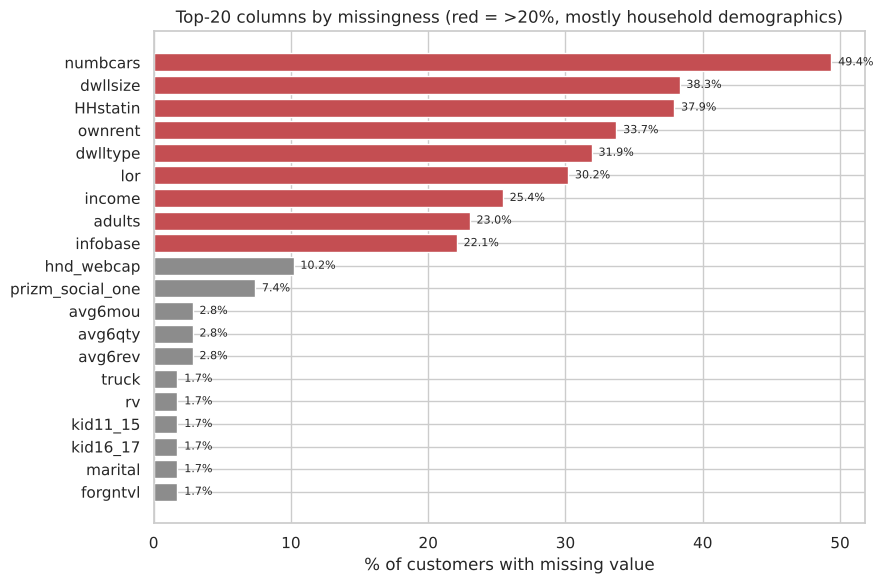

In [3]:
cat_cols_raw = df.select_dtypes(exclude="number").columns.tolist()
num_cols_raw = [c for c in df.select_dtypes(include="number").columns if c not in ("churn", "Customer_ID")]
print(f"{len(num_cols_raw)} numeric, {len(cat_cols_raw)} categorical columns")
print("Categorical:", cat_cols_raw)

miss = df.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0] * 100
fig, ax = plt.subplots(figsize=(9, 6))
top = miss.head(20)
ax.barh(top.index[::-1], top.values[::-1], color=["#C44E52" if v > 20 else "#8C8C8C" for v in top.values[::-1]])
ax.set_xlabel("% of customers with missing value")
ax.set_title("Top-20 columns by missingness (red = >20%, mostly household demographics)")
for i, v in enumerate(top.values[::-1]):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8)
plt.tight_layout(); plt.show()

**Reading:** missingness is concentrated in the third-party **household demographics** (`numbcars`, `dwllsize`, `HHstatin`, `ownrent`, `lor`, `income`, …: 20–50% missing). Usage and billing columns are almost complete. We will **not drop** these columns blindly: whether a customer could be matched to the demographic database may itself carry signal. Instead, missing values are kept as `NaN` (gradient-boosting handles them natively) and a *count of missing demographics* feature is added.

### 3.2 Implausible values

In [4]:
checks = {
    "eqpdays < 0 (handset age negative)": (df.eqpdays < 0).sum(),
    "rev_Mean < 0 (negative revenue)": (df.rev_Mean < 0).sum(),
    "totmrc_Mean < 0 (negative recurring charge)": (df.totmrc_Mean < 0).sum(),
    "rev_Mean > 1000 $/month": (df.rev_Mean > 1000).sum(),
}
display(pd.Series(checks, name="# customers").to_frame())
df[["rev_Mean", "mou_Mean", "totmrc_Mean", "eqpdays", "months", "change_mou", "custcare_Mean", "hnd_price"]].describe().T.round(1)

,# customers
eqpdays < 0 (handset age negative),133
rev_Mean < 0 (negative revenue),5
totmrc_Mean < 0 (negative recurring charge),23
rev_Mean > 1000 $/month,3


,count,mean,std,min,25%,50%,75%,max
rev_Mean,99643.0,58.7,46.3,-6.2,33.3,48.2,70.8,3843.3
mou_Mean,99643.0,513.6,525.2,0.0,150.8,355.5,703.0,12206.8
totmrc_Mean,99643.0,46.2,23.6,-26.9,30.0,45.0,60.0,410.0
eqpdays,99999.0,391.9,256.5,-5.0,212.0,342.0,530.0,1823.0
months,100000.0,18.8,9.7,6.0,11.0,16.0,24.0,61.0
change_mou,99109.0,-13.9,276.1,-3875.0,-87.0,-6.2,63.0,31219.2
custcare_Mean,100000.0,1.8,5.3,0.0,0.0,0.0,1.7,675.3
hnd_price,99153.0,101.9,61.0,10.0,30.0,100.0,150.0,500.0


**Reading:** a handful of negative handset ages / revenues (billing adjustments, data-entry errors) are set to `NaN`. Heavy right tails (revenue up to ~$3,800/month, minutes up to 12,000/month) are real heavy users — tree models are insensitive to them; for logistic regression we apply a signed-log transform, and for charts we bin by quantile so extreme values do not distort the picture.

### 3.3 Leakage check
A single feature that predicts churn "too well" would suggest it is recorded *after* the churn event. We compute the stand-alone ROC-AUC of every numeric column.

In [5]:
def single_auc(x, y):
    m = x.notna()
    a = roc_auc_score(y[m], x[m])
    return max(a, 1 - a)

uni_auc = pd.Series({c: single_auc(df[c], df.churn) for c in num_cols_raw}).sort_values(ascending=False)
print("Highest single-feature AUCs:")
print(uni_auc.head(10).round(3).to_string())
rho = df[["Customer_ID", "months"]].corr(method="spearman").iloc[0, 1]
print(f"\nCustomer_ID vs tenure (Spearman rho): {rho:.2f}")

Highest single-feature AUCs:
eqpdays            0.574
hnd_price          0.558
totmrc_Mean        0.542
mou_opkv_Mean      0.541
mou_cvce_Mean      0.541
mou_Mean           0.539
iwylis_vce_Mean    0.536
mouiwylisv_Mean    0.536
complete_Mean      0.536
opk_vce_Mean       0.536

Customer_ID vs tenure (Spearman rho): -0.83


**Reading:** the best single column reaches an AUC of only ~0.6. No feature is "too good to be true", so there is **no evidence of target leakage**; churn is a multi-factor outcome that needs a multivariate model.

`Customer_ID` is **not** used as a feature: IDs were issued in sign-up order (Spearman ρ ≈ −0.83 with tenure), so the ID only re-encodes tenure — and possibly how the sample was drawn — which a production model must not rely on.

---
## 4. Exploratory Data Analysis

### 4.1 Target balance

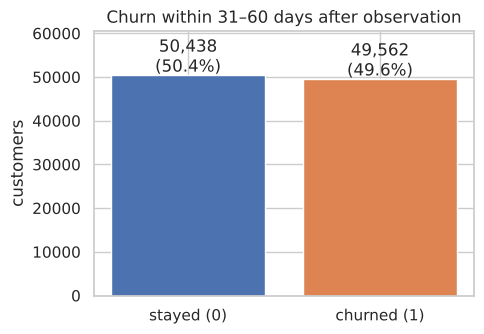

Overall churn rate: 49.6%


In [6]:
rate = df.churn.mean()
fig, ax = plt.subplots(figsize=(5, 3.5))
vc = df.churn.value_counts().sort_index()
ax.bar(["stayed (0)", "churned (1)"], vc.values, color=[PALETTE["stayed"], PALETTE["churned"]])
for i, v in enumerate(vc.values):
    ax.text(i, v + 800, f"{v:,}\n({v/len(df):.1%})", ha="center")
ax.set_ylim(0, vc.max() * 1.2); ax.set_ylabel("customers")
ax.set_title("Churn within 31–60 days after observation")
plt.tight_layout(); plt.show()
print(f"Overall churn rate: {rate:.1%}")

**Reading:** ~50% churn — far higher than the 1.5–3%/month typical of real operators. The sample was almost certainly **balanced by design** (churners over-sampled, as in the Duke/Teradata tournament data [6]). Consequences:
1. Accuracy is a usable metric here, but **ROC-AUC** (ranking quality, independent of the 50/50 sampling) is our primary metric.
2. When we translate results into money (Section 9) we **re-weight to a realistic base churn rate** rather than assume half the customers leave.

### 4.2 Testing the hypotheses: churn rate by numeric driver
Each panel splits customers into 10 equal-size groups (deciles) of a feature and shows the churn rate per group. Dashed line = average churn.

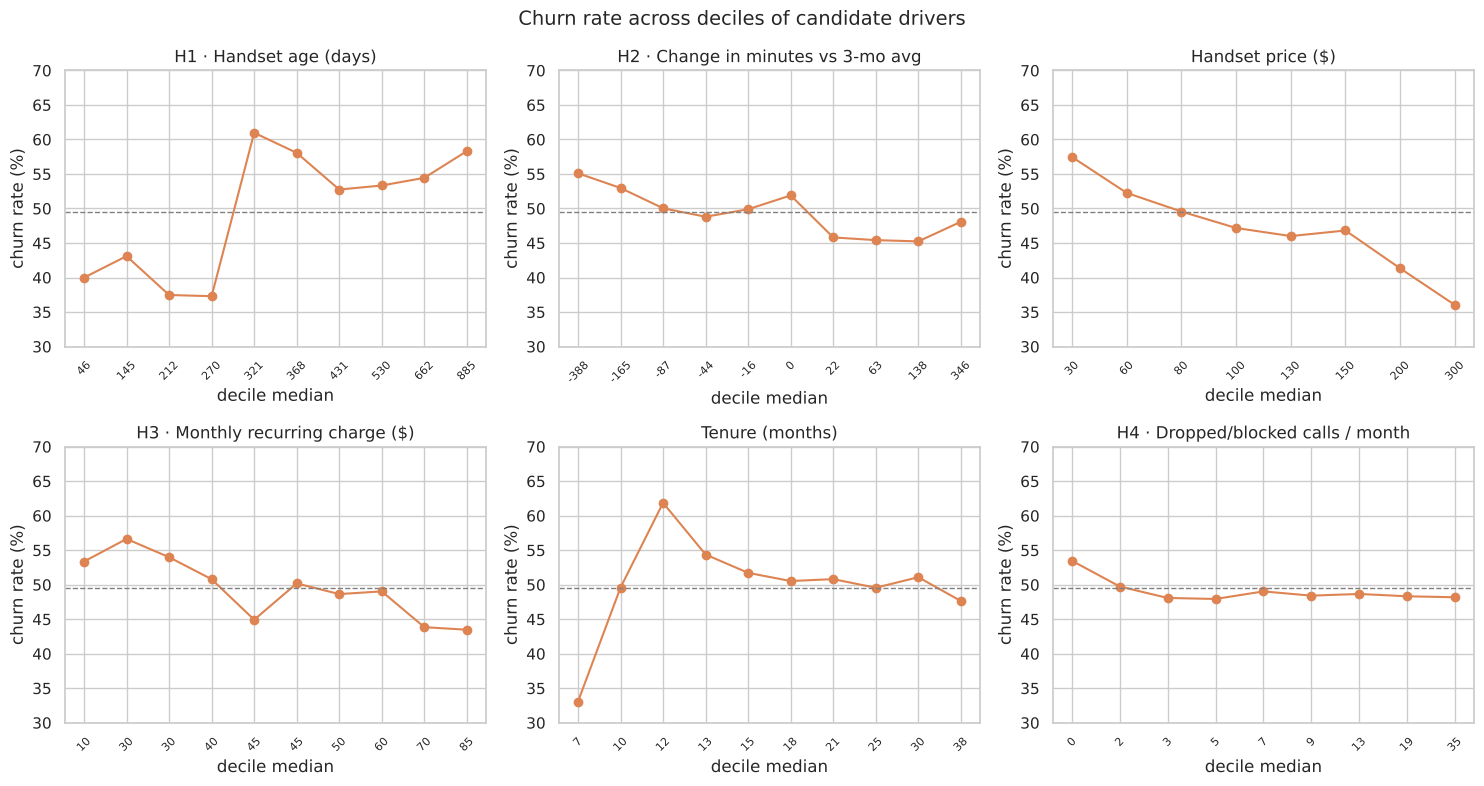

In [7]:
def churn_by_quantile(col, q=10, data=df):
    s = data[[col, "churn"]].dropna()
    s["bin"] = pd.qcut(s[col], q=q, duplicates="drop")
    g = s.groupby("bin", observed=True).agg(churn=("churn", "mean"), n=("churn", "size"), mid=(col, "median"))
    return g

drivers = {
    "eqpdays": "H1 · Handset age (days)",
    "change_mou": "H2 · Change in minutes vs 3-mo avg",
    "hnd_price": "Handset price ($)",
    "totmrc_Mean": "H3 · Monthly recurring charge ($)",
    "months": "Tenure (months)",
    "drop_blk_Mean": "H4 · Dropped/blocked calls / month",
}
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (col, title) in zip(axes.ravel(), drivers.items()):
    g = churn_by_quantile(col)
    ax.plot(range(len(g)), g.churn * 100, marker="o", color=PALETTE["churned"])
    ax.axhline(rate * 100, ls="--", color="grey", lw=1)
    ax.set_xticks(range(len(g))); ax.set_xticklabels([f"{m:,.0f}" for m in g.mid], rotation=45, fontsize=8)
    ax.set_title(title); ax.set_ylabel("churn rate (%)"); ax.set_xlabel("decile median")
    ax.set_ylim(30, 70)
plt.suptitle("Churn rate across deciles of candidate drivers", fontsize=14)
plt.tight_layout(); plt.show()

In [8]:
summary = []
for col in drivers:
    g = churn_by_quantile(col)
    summary.append({"feature": col, "lowest-decile churn": g.churn.iloc[0], "highest-decile churn": g.churn.iloc[-1],
                    "spread (pp)": (g.churn.max() - g.churn.min()) * 100})
pd.DataFrame(summary).set_index("feature").style.format({"lowest-decile churn": "{:.1%}", "highest-decile churn": "{:.1%}", "spread (pp)": "{:.1f}"})

,lowest-decile churn,highest-decile churn,spread (pp)
feature,,,
eqpdays,40.0%,58.3%,23.7
change_mou,55.1%,48.1%,9.9
hnd_price,57.5%,36.0%,21.4
totmrc_Mean,53.4%,43.5%,13.2
months,33.1%,47.6%,28.8
drop_blk_Mean,53.5%,48.2%,5.5


**Reading (hypothesis by hypothesis):**
- **H1 Handset age — confirmed, strongest lever.** There is a clear **step at ~1 year**: customers with handsets younger than ~11 months churn at ~37–43%, while those past the 1-year mark churn at ~53–61%. This is the single strongest stand-alone signal (AUC 0.57).
- **H2 Usage decline — confirmed.** The decile with the sharpest drop in minutes has the highest churn; customers whose usage is stable or growing churn the least. Usage decline is an *early-warning* signal.
- **Handset price — cheaper handsets churn more** (low-value devices, low lock-in).
- **H3 Recurring charge — lower plans churn more**: low-commitment plans are easier to leave; heavy plan users are more locked-in.
- **Tenure** has a non-linear pattern (risk around typical contract-end months, ~10–12 months).
- **H4 Network quality — not supported.** Only the very lowest decile (customers with almost no calls) churns more; above that, more dropped/blocked calls go with slightly *lower* churn because the count scales with usage (heavy users drop more calls but are more loyal). We test a **rate** version in Section 6.

### 4.3 Contract-end effect: tenure in months

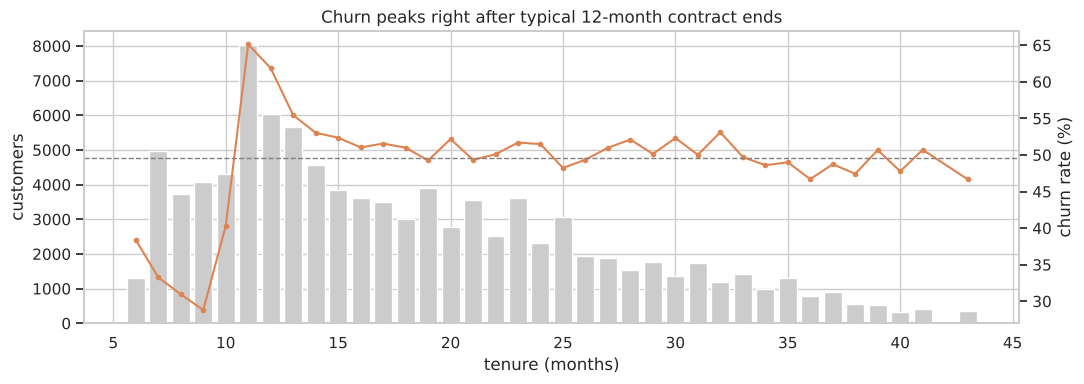

         mean  size
months             
11      0.651  8029
12      0.619  6033
13      0.554  5651
32      0.531  1194
14      0.530  4552


In [9]:
t = df.groupby("months").churn.agg(["mean", "size"]).query("size >= 300")
fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(t.index, t["size"], color="#CCCCCC", label="customers")
ax1.set_ylabel("customers"); ax1.set_xlabel("tenure (months)")
ax2 = ax1.twinx()
ax2.plot(t.index, t["mean"] * 100, color=PALETTE["churned"], marker="o", ms=3, label="churn rate")
ax2.axhline(rate * 100, ls="--", color="grey", lw=1); ax2.set_ylabel("churn rate (%)"); ax2.grid(False)
ax1.set_title("Churn peaks right after typical 12-month contract ends")
plt.tight_layout(); plt.show()
print(t.sort_values("mean", ascending=False).head(5).round(3))

**Reading:** churn spikes at **~11–12 months** — the end of a one-year contract — and is lowest in the first months (customers still under contract). Timing matters: a retention offer must arrive **before** the contract-end window.

### 4.4 Categorical segments

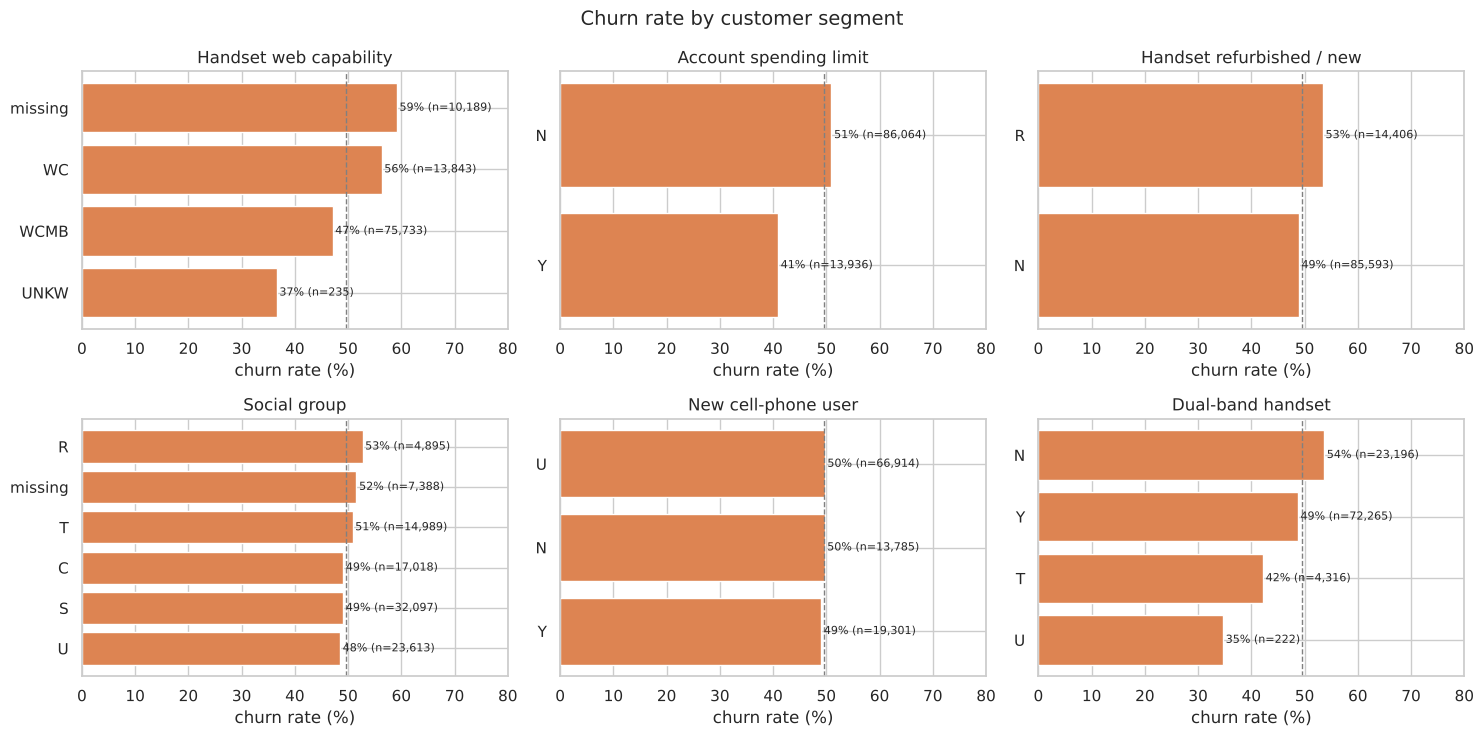

In [10]:
seg_cols = {"hnd_webcap": "Handset web capability", "asl_flag": "Account spending limit",
            "refurb_new": "Handset refurbished / new", "prizm_social_one": "Social group",
            "new_cell": "New cell-phone user", "dualband": "Dual-band handset"}
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, (col, title) in zip(axes.ravel(), seg_cols.items()):
    g = df.assign(**{col: df[col].fillna("missing")}).groupby(col).churn.agg(["mean", "size"])
    g = g[g["size"] >= 200].sort_values("mean")
    ax.barh(g.index.astype(str), g["mean"] * 100, color=PALETTE["churned"])
    ax.axvline(rate * 100, ls="--", color="grey", lw=1)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(m * 100 + 0.5, i, f"{m:.0%} (n={n:,})", va="center", fontsize=8)
    ax.set_xlim(0, 80); ax.set_title(title); ax.set_xlabel("churn rate (%)")
plt.suptitle("Churn rate by customer segment", fontsize=14)
plt.tight_layout(); plt.show()

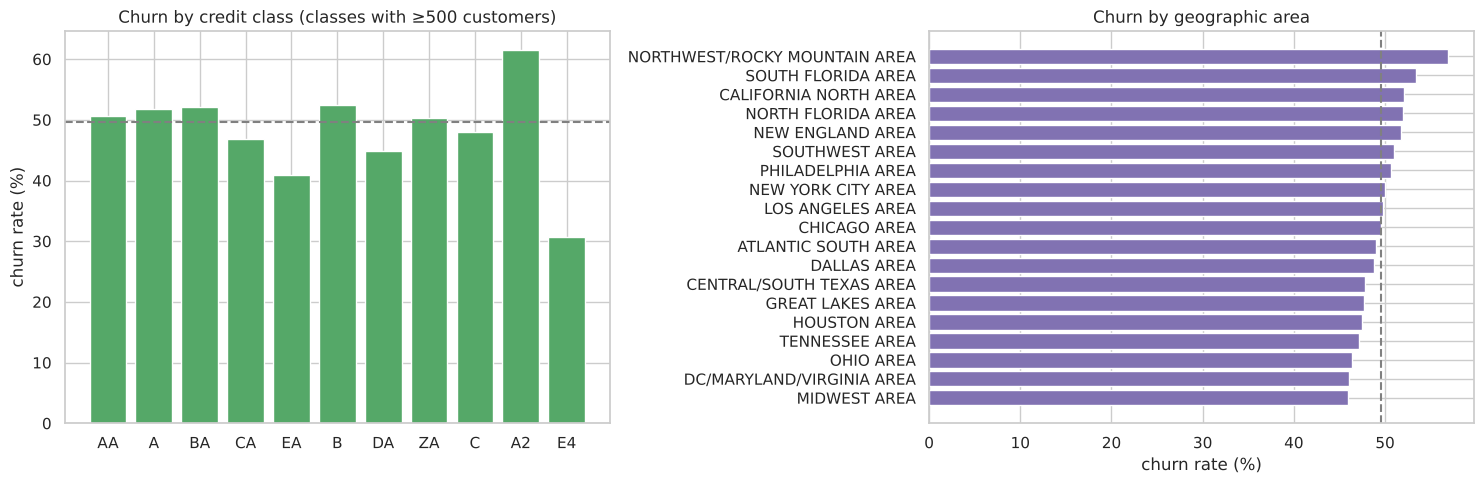

In [11]:
cc = df.groupby("crclscod").churn.agg(["mean", "size"]).query("size >= 500").sort_values("size", ascending=False)
area = df.groupby("area").churn.agg(["mean", "size"]).sort_values("mean")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(cc.index, cc["mean"] * 100, color="#55A868"); axes[0].axhline(rate * 100, ls="--", color="grey")
axes[0].set_title("Churn by credit class (classes with ≥500 customers)"); axes[0].set_ylabel("churn rate (%)")
axes[1].barh(area.index, area["mean"] * 100, color="#8172B2"); axes[1].axvline(rate * 100, ls="--", color="grey")
axes[1].set_title("Churn by geographic area"); axes[1].set_xlabel("churn rate (%)")
plt.tight_layout(); plt.show()

**Reading:**
- Customers whose handset web capability is **unknown/missing (59%) or "WC" (56%) churn most**, versus 47% for "WCMB" (the most common, newer handsets) — consistent with H1: older device generations churn more.
- Accounts **without a spending limit** churn more than those with one (spending-limited accounts are often prepaid/credit-controlled, with fewer switching options).
- **Refurbished handsets** churn more than new ones.
- Credit class and area show spreads of several percentage points: useful model inputs, but not as actionable as handset and usage signals.

### 4.5 Redundant features

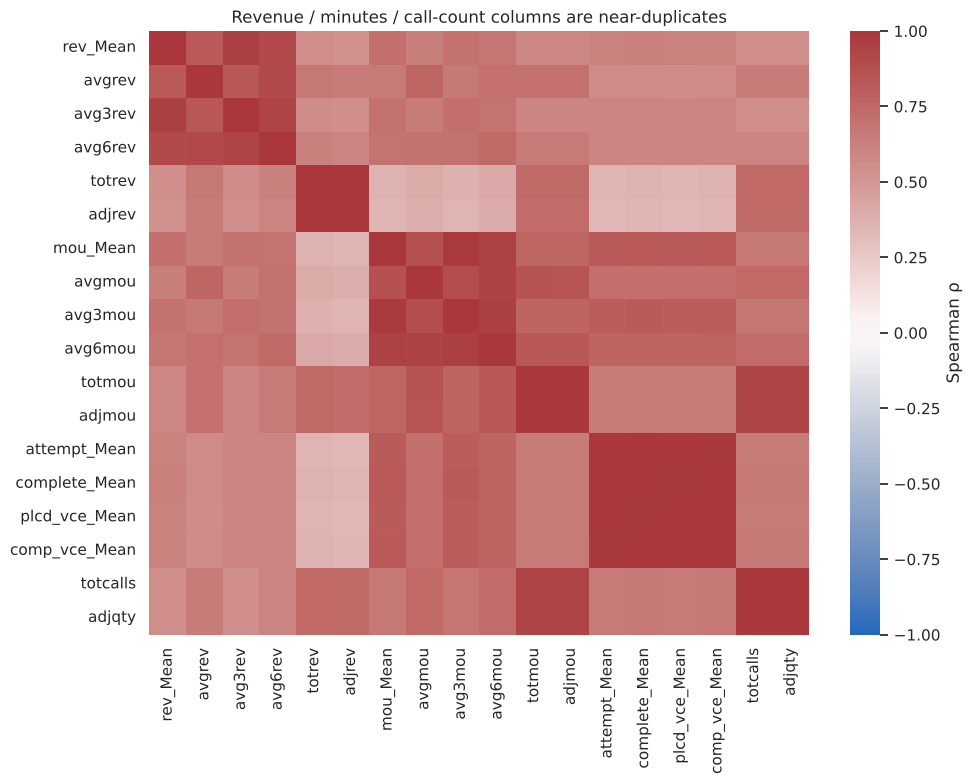

In [12]:
grp = ["rev_Mean", "avgrev", "avg3rev", "avg6rev", "totrev", "adjrev", "mou_Mean", "avgmou", "avg3mou", "avg6mou",
       "totmou", "adjmou", "attempt_Mean", "complete_Mean", "plcd_vce_Mean", "comp_vce_Mean", "totcalls", "adjqty"]
corr = df[grp].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Spearman ρ"})
ax.set_title("Revenue / minutes / call-count columns are near-duplicates")
plt.tight_layout(); plt.show()

**Reading:** revenue, minutes and call-count columns form three tight clusters (ρ > 0.9). A tree model copes with this, but feature-importance becomes split across proxies. The *useful* information is **not the level** of usage but its **change over time** (recent vs lifetime average) — which motivates the trend features in Section 6.

### 4.6 EDA conclusions → pain points
1. **Ageing handsets** are the clearest, most actionable churn driver.
2. **Falling usage** precedes churn → an early-warning signal exists.
3. **Contract-end timing** (~month 11–12) concentrates risk.
4. **Low-commitment, low-value plans** (low recurring charge, cheap/refurbished handset) are less sticky.
5. No single variable separates churners (best AUC ≈ 0.6) → a **multivariate ML model** is needed to rank customers by risk.

---
## 5. Problem Definition

**Business objective:** reduce revenue lost to churn by spending a limited retention budget **only on the customers most likely to leave** and with the right offer.

**ML task:** binary classification — predict `churn` (1 = leaves 31–60 days after the observation date) from information available at the observation date. The 31–60 day horizon leaves a **one-month action window** for a retention campaign.

**Why churn and not revenue?** EDA shows churn is ~50% of the sample and strongly linked to actionable levers (handset, plan, usage decline). A churn score directly answers the operational question "whom should the retention team call this month?".

**Metrics**
- **ROC-AUC (primary):** probability that a random churner is ranked above a random stayer. It measures *ranking quality* — exactly what a campaign targeting the top-X% needs — and is unaffected by the artificial 50/50 sampling.
- **Accuracy, precision, recall, F1** at the 0.5 threshold: easy-to-explain secondary metrics (meaningful here since classes are balanced).
- **Lift in top deciles & campaign profit:** the business metric (Section 9), following the profit-driven evaluation of Verbeke et al. [5].

---
## 6. Feature Engineering

The first version of the model used the 20 features in the upper part of the table. The **17 features in the lower part were added to make the model more accurate** — most importantly the *latest-month change* features, which turned out to be the strongest new signal (Section 7.2).

| Feature | Formula | Business meaning |
|---|---|---|
| `eqp_to_tenure` | handset age / tenure in days | has the customer *ever* upgraded with us? |
| `eqp_over_1y`, `eqp_over_2y` | handset age > 365 / 730 days | upgrade-due flags |
| `mou_trend_3v6`, `mou_trend_3vlife` | recent 3-mo minutes / 6-mo or lifetime avg | usage decline (early warning) |
| `rev_trend_3vlife`, `qty_trend_3vlife` | same for revenue / calls | spend & activity decline |
| `mou_now_vs_life` | current minutes / lifetime avg | usage now vs. the customer's normal |
| `overage_share` | overage revenue / total revenue | plan too small → bill shock |
| `mrc_share` | recurring charge / total revenue | how "fixed" the bill is |
| `rev_per_min` | revenue / minutes | effective price paid |
| `drop_rate`, `fail_rate`, `block_rate` | dropped or blocked / attempted calls | network quality as a **rate** (fixes the H4 confound) |
| `custcare_per_100` | care calls per 100 calls | complaint intensity |
| `unanswered_rate` | unanswered / placed calls | |
| `phones_per_year` | handsets issued / tenure (years) | upgrade frequency |
| `subs_inactive` | unique subs − active subs | household lines already lost |
| `n_missing_demo` | count of missing demographics | data-match quality |
| `contract_end_window` | tenure in 10–13 months | contract-end risk |
| **Added to improve accuracy** | | |
| `mou_now_vs_3`, `rev_now_vs_3` | current minutes / revenue ÷ previous-3-month average | **sudden drop in the latest month** — the strongest early warning |
| `change_mou_rel`, `change_rev_rel` | reported change in minutes / revenue ÷ previous-3-month average | the same change as a *percentage*, comparable for light and heavy users |
| `tenure_at_handset` | tenure − handset age (months) | did the customer join with this handset or upgrade later? |
| `months_mod12` | tenure modulo 12 | position in the yearly contract cycle |
| `hnd_price_to_mrc` | handset price / recurring charge | handset value relative to the plan |
| `var_rev` | revenue − recurring charge | usage-driven (variable) part of the bill |
| `ovr_mou_share` | overage minutes / total minutes | plan too small |
| `mou_per_mrc` | minutes per $ of recurring charge | plan utilisation |
| `rev_3_vs_mrc` | 3-month revenue / recurring charge | bill vs. plan price |
| `recv_to_plcd` | received / placed calls | inbound vs. outbound use |
| `complete_rate` | completed / placed calls | call success (network quality) |
| `avg_call_len` | minutes per completed call | calling style |
| `peak_share` | peak / all voice calls | business vs. personal use |
| `w2w_share` | wireless-to-wireless / placed calls | share of mobile-to-mobile calling |
| `short_in_share` | inbound calls < 1 min / received calls | very short (missed / voicemail-like) calls |

Categoricals are kept as pandas `category` (missing kept as its own state) for the tree models, as strings for CatBoost, and one-hot encoded for logistic regression. `Customer_ID` is dropped.

In [13]:
DEMO = ["numbcars", "dwllsize", "HHstatin", "ownrent", "dwlltype", "lor", "income", "adults", "infobase"]
ADDED = ["mou_now_vs_3", "rev_now_vs_3", "change_mou_rel", "change_rev_rel",              # latest-month change
         "tenure_at_handset", "months_mod12", "hnd_price_to_mrc",                         # handset / contract timing
         "var_rev", "ovr_mou_share", "mou_per_mrc", "rev_3_vs_mrc",                       # plan fit
         "recv_to_plcd", "complete_rate", "avg_call_len", "peak_share", "w2w_share", "short_in_share"]  # calling pattern

def engineer(data: pd.DataFrame) -> pd.DataFrame:
    d = data.copy()
    # cleaning
    d.loc[d.eqpdays < 0, "eqpdays"] = np.nan
    for c in ["rev_Mean", "totmrc_Mean"]:
        d.loc[d[c] < 0, c] = np.nan
    # handset
    d["eqp_to_tenure"] = d.eqpdays / (d.months * 30.4)
    d["eqp_over_1y"] = (d.eqpdays > 365).astype(float)
    d["eqp_over_2y"] = (d.eqpdays > 730).astype(float)
    d["phones_per_year"] = d.phones / (d.months / 12)
    # behaviour change
    d["mou_trend_3v6"] = d.avg3mou / (d.avg6mou + 1)
    d["mou_trend_3vlife"] = d.avg3mou / (d.avgmou + 1)
    d["rev_trend_3vlife"] = d.avg3rev / (d.avgrev + 1)
    d["qty_trend_3vlife"] = d.avg3qty / (d.avgqty + 1)
    d["mou_now_vs_life"] = d.mou_Mean / (d.avgmou + 1)
    # pricing
    d["overage_share"] = d.ovrrev_Mean / (d.rev_Mean + 1)
    d["mrc_share"] = d.totmrc_Mean / (d.rev_Mean + 1)
    d["rev_per_min"] = d.rev_Mean / (d.mou_Mean + 1)
    # quality as rates
    d["drop_rate"] = d.drop_vce_Mean / (d.plcd_vce_Mean + 1)
    d["block_rate"] = d.blck_vce_Mean / (d.plcd_vce_Mean + 1)
    d["fail_rate"] = d.drop_blk_Mean / (d.attempt_Mean + 1)
    d["unanswered_rate"] = d.unan_vce_Mean / (d.plcd_vce_Mean + 1)
    d["custcare_per_100"] = 100 * d.custcare_Mean / (d.attempt_Mean + 1)
    # household / contract
    d["subs_inactive"] = d.uniqsubs - d.actvsubs
    d["n_missing_demo"] = d[DEMO].isna().sum(axis=1)
    d["contract_end_window"] = d.months.between(10, 13).astype(float)

    # ---- added to improve accuracy -------------------------------------------------
    # latest-month change vs. the previous 3 months (sudden drops are the strongest warning)
    d["mou_now_vs_3"] = d.mou_Mean / (d.avg3mou + 1)
    d["rev_now_vs_3"] = d.rev_Mean / (d.avg3rev + 1)
    d["change_mou_rel"] = d.change_mou / (d.avg3mou + 1)
    d["change_rev_rel"] = d.change_rev / (d.avg3rev + 1)
    # handset / contract timing
    d["tenure_at_handset"] = d.months - d.eqpdays / 30.4
    d["months_mod12"] = d.months % 12
    d["hnd_price_to_mrc"] = d.hnd_price / (d.totmrc_Mean + 1)
    # plan fit
    d["var_rev"] = d.rev_Mean - d.totmrc_Mean
    d["ovr_mou_share"] = d.ovrmou_Mean / (d.mou_Mean + 1)
    d["mou_per_mrc"] = d.mou_Mean / (d.totmrc_Mean + 1)
    d["rev_3_vs_mrc"] = d.avg3rev / (d.totmrc_Mean + 1)
    # calling pattern
    d["recv_to_plcd"] = d.recv_vce_Mean / (d.plcd_vce_Mean + 1)
    d["complete_rate"] = d.comp_vce_Mean / (d.plcd_vce_Mean + 1)
    d["avg_call_len"] = d.mou_cvce_Mean / (d.comp_vce_Mean + 1)
    d["peak_share"] = d.peak_vce_Mean / (d.peak_vce_Mean + d.opk_vce_Mean + 1)
    d["w2w_share"] = d.owylis_vce_Mean / (d.plcd_vce_Mean + 1)
    d["short_in_share"] = d.inonemin_Mean / (d.recv_vce_Mean + 1)
    d = d.replace([np.inf, -np.inf], np.nan)
    return d

data = engineer(df).drop(columns=["Customer_ID"])
CAT_COLS = data.select_dtypes(exclude="number").columns.tolist()
for c in CAT_COLS:
    data[c] = data[c].astype("category")
FEATURES = [c for c in data.columns if c != "churn"]
FEATURES_V1 = [c for c in FEATURES if c not in ADDED]       # feature set of the first model version
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]
print(f"{len(FEATURES)} features ({len(NUM_COLS)} numeric, {len(CAT_COLS)} categorical); "
      f"first version used {len(FEATURES_V1)}, {len(ADDED)} added")

new_feats = ["mou_now_vs_3", "change_mou_rel", "rev_now_vs_3", "change_rev_rel",
             "mou_trend_3vlife", "eqp_to_tenure", "rev_per_min", "drop_rate", "custcare_per_100"]
print("\nStand-alone AUC of engineered features vs. raw counterparts:")
cmp = pd.DataFrame({"AUC": [single_auc(data[c], data.churn) for c in new_feats]}, index=new_feats)
cmp["raw counterpart"] = ["mou_Mean", "change_mou", "rev_Mean", "change_rev",
                          "avg3mou", "eqpdays", "rev_Mean", "drop_vce_Mean", "custcare_Mean"]
cmp["raw AUC"] = [single_auc(data[c], data.churn) for c in cmp["raw counterpart"]]
cmp.round(3)

135 features (114 numeric, 21 categorical); first version used 118, 17 added

Stand-alone AUC of engineered features vs. raw counterparts:


,AUC,raw counterpart,raw AUC
mou_now_vs_3,0.553,mou_Mean,0.539
change_mou_rel,0.543,change_mou,0.530
rev_now_vs_3,0.512,rev_Mean,0.515
change_rev_rel,0.506,change_rev,0.505
mou_trend_3vlife,0.545,avg3mou,0.534
eqp_to_tenure,0.541,eqpdays,0.574
rev_per_min,0.548,rev_Mean,0.515
drop_rate,0.506,drop_vce_Mean,0.514
custcare_per_100,0.525,custcare_Mean,0.529


**Reading:** stand-alone AUCs are small for every feature (as expected — churn is multi-factor), but the engineered features beat their raw counterparts where it matters: the **latest-month change** features (`mou_now_vs_3` 0.553 vs 0.539 for raw minutes; `change_mou_rel` 0.543 vs 0.530 for the raw change), the lifetime **trend** (`mou_trend_3vlife`) and the **price** (`rev_per_min`) features. The quality *rates* remain weak, confirming that network quality is **not** a main churn driver for Company A — a useful negative finding (budget should go to handset/plan offers, not network-quality messaging). The real test of the features is the multivariate model below (Section 7.2 measures their contribution).

### 6.1 Train / test split
70% for training (with 5-fold cross-validation for tuning, model selection and the ensemble weights), 30% held out and touched only once for the final scores. Stratified on churn.

In [14]:
X, y = data[FEATURES], data["churn"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=SEED, stratify=y)
print("train:", X_train.shape, " test:", X_test.shape, " churn rate train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv.split(X_train, y_train))   # the same 5 folds are used for every model

train: (70000, 135)  test: (30000, 135)  churn rate train/test: 0.496 0.496


---
## 7. Modelling

We compare models of increasing flexibility, then combine the best ones:

| Model | Why it is a candidate |
|---|---|
| **Baseline** (always predict majority) | the "no-model" reference: AUC 0.5 |
| **Logistic Regression** | transparent, linear; shows how far a simple scorecard gets |
| **Random Forest** [10] | non-linear, robust to outliers, little tuning |
| **XGBoost** [8] | gradient-boosted trees; handles missing values and interactions; tutorial baseline |
| **LightGBM** [9] | gradient boosting with native categorical support; fast on 100k rows |
| **CatBoost** [13] | gradient boosting with "ordered" target statistics for categoricals — strong on mixed tabular data like ours |
| **Soft-voting ensemble** [15] | average of the churn probabilities of LightGBM, CatBoost and XGBoost — their errors partly cancel out |

Gradient-boosted trees are the standard choice for tabular data with mixed types, missing values and heavy tails, which is exactly this dataset.

**How the boosted models were made more accurate**
1. **More informative features** (Section 6) — especially the latest-month change in usage and revenue.
2. **Hyper-parameter tuning.** LightGBM was tuned with Optuna [14]: 40 trials of a Bayesian (TPE) search, each scored by **5-fold cross-validated ROC-AUC on the training set only**, with early stopping to choose the number of trees. The search code is in the optional cell below (`RUN_TUNING = False`, ≈30 min); its best values (rounded) are written into the model definitions so the notebook stays fast and reproducible. The search clearly preferred **smaller, more regularised trees** (22 leaves, an L1 penalty, 45% of the features per tree), so XGBoost was re-configured the same way (depth 5, L1 penalty, 45% of features) and checked on the same folds. CatBoost's number of trees was read off its validation learning curve. The final models use a smaller learning rate with proportionally more trees.
3. **Ensembling**: the ensemble weights are chosen on the out-of-fold predictions of the training set — the 30% test set is used **once**, at the very end, to report the scores.

In [15]:
# ---- input conversions (each model family wants categoricals in a different form)
def to_obj(X):    # sklearn imputers prefer object over category
    X = X.copy(); X[CAT_COLS] = X[CAT_COLS].astype(object); return X

def to_codes(X):  # integer codes for the random forest
    X = X.copy()
    for c in CAT_COLS: X[c] = X[c].cat.codes
    return X.fillna(-999)

def to_str(X):    # CatBoost: categories as strings, missing as its own level
    X = X.copy()
    for c in CAT_COLS: X[c] = X[c].astype(object).fillna("missing").astype(str)
    return X

# ---- Logistic regression pipeline (needs imputation, scaling, one-hot)
signed_log = FunctionTransformer(lambda a: np.sign(a) * np.log1p(np.abs(a)), feature_names_out="one-to-one")
lr_pre = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), signed_log, StandardScaler()), NUM_COLS),
    ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="missing"),
                          OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100)), CAT_COLS),
])
logreg = make_pipeline(FunctionTransformer(to_obj), lr_pre, LogisticRegression(max_iter=2000, C=0.5))

# ---- Random forest (ordinal-encoded categoricals)
rf = make_pipeline(FunctionTransformer(to_codes),
                   RandomForestClassifier(n_estimators=300, min_samples_leaf=10, max_features="sqrt", n_jobs=-1, random_state=SEED))

# ---- XGBoost (native missing + categorical support; shallow, regularised trees as found by the LightGBM search)
XGB_PARAMS = dict(n_estimators=1600, learning_rate=0.02, max_depth=5, min_child_weight=8, subsample=0.9, colsample_bytree=0.45, reg_alpha=3.0, reg_lambda=1.0, gamma=0.1, max_bin=256)
xgb = XGBClassifier(**XGB_PARAMS, tree_method="hist", enable_categorical=True, max_cat_to_onehot=1,
                    eval_metric="auc", n_jobs=-1, random_state=SEED)

# ---- LightGBM (native categorical support; tuned with Optuna, see below)
LGB_PARAMS = dict(n_estimators=1600, learning_rate=0.02, num_leaves=22, min_child_samples=33, colsample_bytree=0.45, subsample=0.94, reg_alpha=3.23, reg_lambda=0.11, min_split_gain=0.08, max_bin=255, cat_smooth=66.0, cat_l2=46.0, min_data_per_group=162, max_cat_threshold=62)
lgbm = lgb.LGBMClassifier(**LGB_PARAMS, subsample_freq=1, n_jobs=-1, random_state=SEED, verbose=-1)

# ---- CatBoost (built-in encoding of categoricals). Small wrapper so that sklearn's clone() works
#      (CatBoost copies its `cat_features` argument, which clone() does not allow).
class CatBoostModel(ClassifierMixin, BaseEstimator):
    def __init__(self, iterations=1000, learning_rate=0.05, depth=6, l2_leaf_reg=3.0):
        self.iterations, self.learning_rate, self.depth, self.l2_leaf_reg = iterations, learning_rate, depth, l2_leaf_reg
    def fit(self, X, y):
        self.model_ = CatBoostClassifier(iterations=self.iterations, learning_rate=self.learning_rate, depth=self.depth,
                                         l2_leaf_reg=self.l2_leaf_reg, cat_features=CAT_COLS, random_seed=SEED,
                                         verbose=0, allow_writing_files=False).fit(to_str(X), y)
        self.classes_ = self.model_.classes_; return self
    def predict_proba(self, X):
        return self.model_.predict_proba(to_str(X))

CAT_PARAMS = dict(iterations=1200, learning_rate=0.05, depth=6, l2_leaf_reg=5.0)
catb = CatBoostModel(**CAT_PARAMS)

models = {"Baseline (majority)": DummyClassifier(strategy="most_frequent"),
          "Logistic Regression": logreg, "Random Forest": rf, "XGBoost": xgb, "LightGBM": lgbm, "CatBoost": catb}

# ---- Soft-voting ensemble of the three boosted models
class SoftVotingEnsemble(ClassifierMixin, BaseEstimator):
    """Churn probability = weighted average of the members' churn probabilities."""
    def __init__(self, members=None, weights=None):
        self.members, self.weights = members, weights
    def fit(self, X, y):
        for m in self.members.values(): m.fit(X, y)
        self.classes_ = np.array([0, 1]); return self
    def predict_proba(self, X):
        w = np.array([self.weights[k] for k in self.members], dtype=float)
        p = np.column_stack([m.predict_proba(X)[:, 1] for m in self.members.values()]) @ (w / w.sum())
        return np.column_stack([1 - p, p])
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

MEMBERS = ["LightGBM", "CatBoost", "XGBoost"]
ENS = "3-model ensemble"

In [16]:
# Optional: re-run the hyper-parameter search behind LGB_PARAMS (≈30 min on 4 CPU cores).
# Every trial is scored by 5-fold cross-validated AUC on the TRAINING set; the test set is never used.
RUN_TUNING = False
if RUN_TUNING:
    try:
        import optuna
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "optuna"]); import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)

    def lgb_objective(trial):
        p = dict(objective="binary", metric="auc", learning_rate=0.04, verbosity=-1, seed=SEED, bagging_freq=1,
                 num_leaves=trial.suggest_int("num_leaves", 8, 128, log=True),
                 min_child_samples=trial.suggest_int("min_child_samples", 20, 600, log=True),
                 feature_fraction=trial.suggest_float("feature_fraction", 0.15, 0.8),
                 bagging_fraction=trial.suggest_float("bagging_fraction", 0.5, 1.0),
                 lambda_l1=trial.suggest_float("lambda_l1", 1e-3, 30, log=True),
                 lambda_l2=trial.suggest_float("lambda_l2", 1e-3, 100, log=True),
                 min_gain_to_split=trial.suggest_float("min_gain_to_split", 0.0, 1.0),
                 max_bin=trial.suggest_categorical("max_bin", [63, 127, 255]),
                 cat_smooth=trial.suggest_float("cat_smooth", 1, 100, log=True),
                 cat_l2=trial.suggest_float("cat_l2", 1, 100, log=True),
                 min_data_per_group=trial.suggest_int("min_data_per_group", 20, 500, log=True),
                 max_cat_threshold=trial.suggest_int("max_cat_threshold", 8, 64, log=True))
        ds = lgb.Dataset(X_train, y_train, categorical_feature=CAT_COLS, params={"max_bin": p["max_bin"], "verbosity": -1})
        r = lgb.cv(p, ds, num_boost_round=4000, folds=folds, callbacks=[lgb.early_stopping(150, verbose=False)])
        trial.set_user_attr("trees", int(np.argmax(r["valid auc-mean"]) + 1))
        return float(np.max(r["valid auc-mean"]))

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=10))
    study.optimize(lgb_objective, n_trials=40)
    print(f"LightGBM: best CV AUC {study.best_value:.4f} with {study.best_trial.user_attrs['trees']} trees at "
          f"learning rate 0.04 ->", study.best_params)
else:
    print("Tuning skipped (RUN_TUNING = False) - using the tuned values stored in LGB_PARAMS.")

Tuning skipped (RUN_TUNING = False) - using the tuned values stored in LGB_PARAMS.


In [17]:
def oof_predict(model, X, y):
    """Out-of-fold churn probabilities: each training customer is scored by a model fitted without them."""
    oof = np.zeros(len(y))
    for tr, va in folds:
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])
        oof[va] = m.predict_proba(X.iloc[va])[:, 1]
    return oof

def fold_aucs(p, y):
    return np.array([roc_auc_score(y.iloc[va], p[va]) for _, va in folds])

oof, cv_rows = {}, []
for name, m in models.items():
    t0 = time.time()
    oof[name] = oof_predict(m, X_train, y_train)
    s = fold_aucs(oof[name], y_train)
    cv_rows.append({"model": name, "CV AUC mean": s.mean(), "CV AUC std": s.std(), "time (s)": time.time() - t0})
    print(f"{name:24s} AUC = {s.mean():.4f} ± {s.std():.4f}   ({time.time()-t0:.0f}s)")

# Ensemble weights: grid search (steps of 0.1) on the out-of-fold predictions - training data only
grid = [(a, b, 1 - a - b) for a in np.arange(0, 1.01, 0.1) for b in np.arange(0, 1.01 - a, 0.1)]
blend = lambda w: sum(wi * oof[k] for wi, k in zip(w, MEMBERS))
w_best = max(grid, key=lambda w: roc_auc_score(y_train, blend(w)))
WEIGHTS = {k: round(float(v), 1) for k, v in zip(MEMBERS, w_best)}
print(f"equal weights: CV AUC {fold_aucs(blend([1/3] * 3), y_train).mean():.4f}  |  "
      f"best grid weights {WEIGHTS}: CV AUC {fold_aucs(blend(list(WEIGHTS.values())), y_train).mean():.4f}")
oof[ENS] = blend([WEIGHTS[k] for k in MEMBERS]) / sum(WEIGHTS.values())
s = fold_aucs(oof[ENS], y_train)
cv_rows.append({"model": ENS, "CV AUC mean": s.mean(), "CV AUC std": s.std(), "time (s)": 0.0})
print(f"{ENS:24s} AUC = {s.mean():.4f} ± {s.std():.4f}")
cv_res = pd.DataFrame(cv_rows).set_index("model")

Baseline (majority)      AUC = 0.5000 ± 0.0000   (0s)


Logistic Regression      AUC = 0.6639 ± 0.0032   (63s)


Random Forest            AUC = 0.6922 ± 0.0017   (118s)


XGBoost                  AUC = 0.7072 ± 0.0024   (80s)


LightGBM                 AUC = 0.7073 ± 0.0025   (81s)


CatBoost                 AUC = 0.7041 ± 0.0025   (437s)


equal weights: CV AUC 0.7083  |  best grid weights {'LightGBM': 0.4, 'CatBoost': 0.2, 'XGBoost': 0.4}: CV AUC 0.7084
3-model ensemble         AUC = 0.7084 ± 0.0025


### 7.1 Final fit and held-out test scores

In [18]:
test_rows, probas = [], {}
for name, m in models.items():
    m.fit(X_train, y_train)
    probas[name] = m.predict_proba(X_test)[:, 1]
models[ENS] = SoftVotingEnsemble({k: models[k] for k in MEMBERS}, WEIGHTS)   # members are already fitted
models[ENS].classes_ = np.array([0, 1])
probas[ENS] = models[ENS].predict_proba(X_test)[:, 1]
for name, p in probas.items():
    yhat = (p >= 0.5).astype(int)
    test_rows.append({"model": name, "Test AUC": roc_auc_score(y_test, p), "Accuracy": accuracy_score(y_test, yhat),
                      "Precision": precision_score(y_test, yhat, zero_division=0), "Recall": recall_score(y_test, yhat),
                      "F1": f1_score(y_test, yhat), "Log-loss": log_loss(y_test, np.clip(p, 1e-6, 1 - 1e-6))})
results = cv_res.join(pd.DataFrame(test_rows).set_index("model"))
results.style.format("{:.4f}", subset=[c for c in results.columns if c != "time (s)"]).format("{:.0f}", subset=["time (s)"]) \
       .highlight_max(subset=["CV AUC mean", "Test AUC", "Accuracy", "F1"], color="#d4edda")

,CV AUC mean,CV AUC std,time (s),Test AUC,Accuracy,Precision,Recall,F1,Log-loss
model,,,,,,,,,
Baseline (majority),0.5000,0.0000,0,0.5000,0.5044,0.0000,0.0000,0.0000,6.8474
Logistic Regression,0.6639,0.0032,63,0.6631,0.6161,0.6141,0.6070,0.6105,0.6509
Random Forest,0.6922,0.0017,118,0.6919,0.6344,0.6287,0.6407,0.6347,0.6333
XGBoost,0.7072,0.0024,80,0.7082,0.6477,0.6454,0.6416,0.6435,0.6207
LightGBM,0.7073,0.0025,81,0.7086,0.6475,0.6443,0.6448,0.6446,0.6204
CatBoost,0.7041,0.0025,437,0.7042,0.6447,0.6418,0.6406,0.6412,0.6232
3-model ensemble,0.7084,0.0025,0,0.7091,0.6481,0.6457,0.6425,0.6441,0.6200


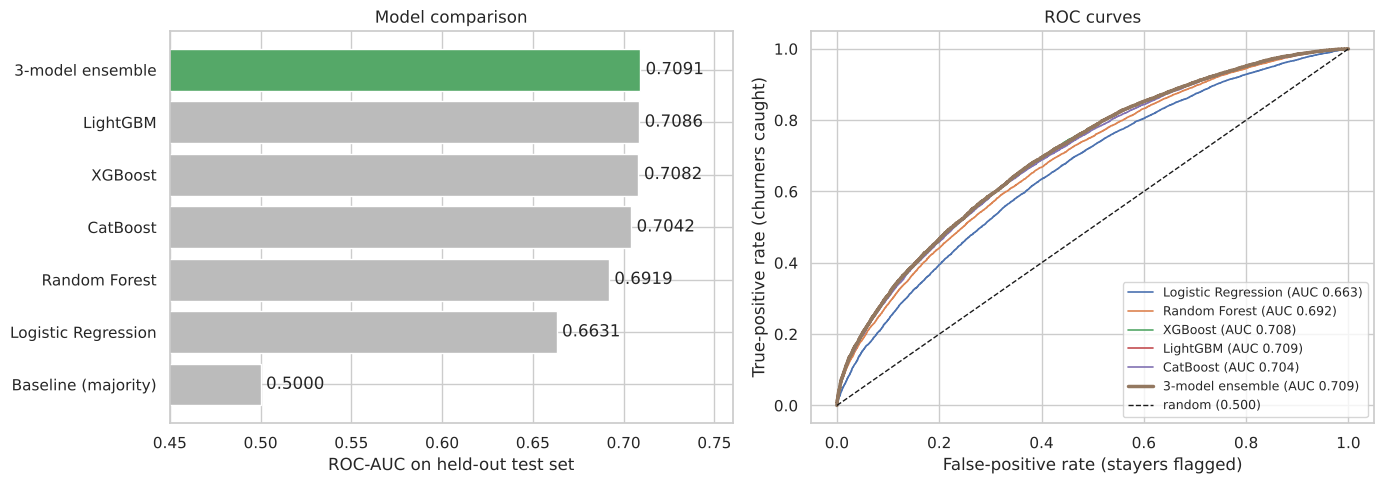

Selected model (best CV AUC): 3-model ensemble  |  CV AUC 0.7084  |  test AUC 0.7091  |  accuracy 0.6481


In [19]:
BEST = results["CV AUC mean"].idxmax()     # selected on cross-validation, NOT on the test set
best_model, p_best = models[BEST], probas[BEST]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = results["Test AUC"].sort_values().index
axes[0].barh(order, results.loc[order, "Test AUC"], color=["#55A868" if n == BEST else "#BBBBBB" for n in order])
for i, v in enumerate(results.loc[order, "Test AUC"]):
    axes[0].text(v + 0.003, i, f"{v:.4f}", va="center")
axes[0].set_xlim(0.45, 0.76); axes[0].set_xlabel("ROC-AUC on held-out test set"); axes[0].set_title("Model comparison")
for name, p in probas.items():
    if name.startswith("Baseline"): continue
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})", lw=2.5 if name == BEST else 1.2)
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="random (0.500)")
axes[1].set_xlabel("False-positive rate (stayers flagged)"); axes[1].set_ylabel("True-positive rate (churners caught)")
axes[1].set_title("ROC curves"); axes[1].legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()
print(f"Selected model (best CV AUC): {BEST}  |  CV AUC {results.loc[BEST, 'CV AUC mean']:.4f}  |  "
      f"test AUC {results.loc[BEST, 'Test AUC']:.4f}  |  accuracy {results.loc[BEST, 'Accuracy']:.4f}")

**Reading:** all ML models clearly beat the baseline (AUC 0.5). The three gradient-boosted models are the strongest single models (CV AUC: LightGBM 0.707, CatBoost 0.704, XGBoost 0.707) — they capture the non-linear patterns seen in EDA (contract-end spike, handset-age thresholds) that logistic regression cannot. **Averaging the three** (weights LightGBM 0.4 / CatBoost 0.2 / XGBoost 0.4, chosen on the training folds) is better than any single model: **CV AUC 0.708 ± 0.002, test AUC 0.709, accuracy 64.8%**, because the models make partly different mistakes that cancel out. The ensemble is selected on cross-validation (not on the test set); cross-validation and test scores agree closely, so the model is **not over-fitted**.

An AUC around 0.70 is in line with what is reported for this type of wireless-carrier churn data [6]: churn is partly driven by events not in the data (competitor offers, moving house), so a perfect model is impossible — but **ranking** is what the campaign needs, and the next sections show the ranking is commercially valuable.

### 7.2 What made the model more accurate?
To show where the accuracy gain comes from, we re-create the **first version** of the model (LightGBM with the original 118 features and untuned settings) and add one improvement at a time — all scored on the **same 5 cross-validation folds** of the training set, plus the held-out test set.

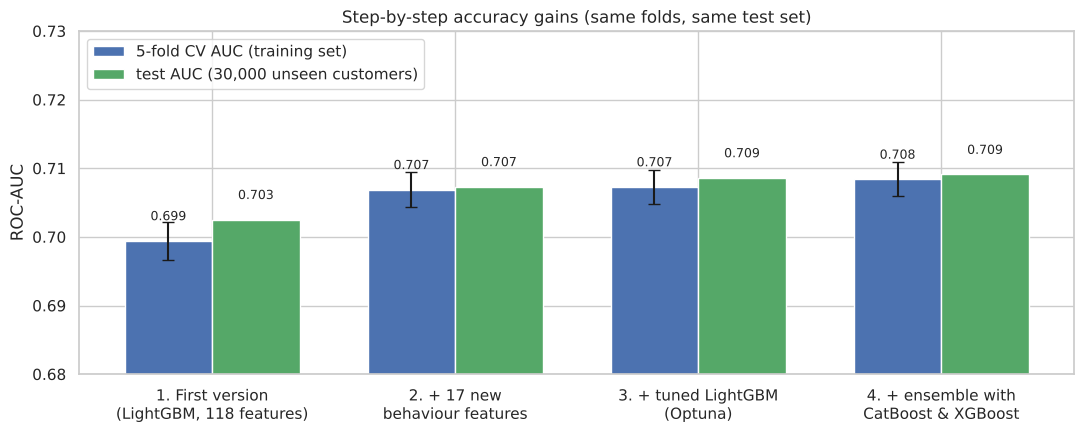

,CV AUC,CV std,Test AUC,Test accuracy,Test F1,Top-10% churn,CV gain vs first version
step,,,,,,,
"1. First version (LightGBM, 118 features)",0.6994,0.0028,0.7025,0.6410,0.6413,0.8063,0.0000
2. + 17 new behaviour features,0.7069,0.0025,0.7073,0.6465,0.6438,0.8170,0.0074
3. + tuned LightGBM (Optuna),0.7073,0.0025,0.7086,0.6475,0.6446,0.8220,0.0079
4. + ensemble with CatBoost & XGBoost,0.7084,0.0025,0.7091,0.6481,0.6441,0.8220,0.0090


In [20]:
lgbm_v1 = lgb.LGBMClassifier(n_estimators=900, learning_rate=0.02, num_leaves=63, min_child_samples=100,
                             subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=2.0,
                             cat_smooth=20, n_jobs=-1, random_state=SEED, verbose=-1)
oof_v1 = oof_predict(lgbm_v1, X_train[FEATURES_V1], y_train)
oof_v1_newfeat = oof_predict(lgbm_v1, X_train, y_train)
p_v1 = clone(lgbm_v1).fit(X_train[FEATURES_V1], y_train).predict_proba(X_test[FEATURES_V1])[:, 1]
p_v1_newfeat = clone(lgbm_v1).fit(X_train, y_train).predict_proba(X_test)[:, 1]

steps = pd.DataFrame({
    "step": [f"1. First version\n(LightGBM, {len(FEATURES_V1)} features)", f"2. + {len(ADDED)} new\nbehaviour features",
             "3. + tuned LightGBM\n(Optuna)", "4. + ensemble with\nCatBoost & XGBoost"],
    "CV AUC": [fold_aucs(o, y_train).mean() for o in [oof_v1, oof_v1_newfeat, oof["LightGBM"], oof[ENS]]],
    "CV std": [fold_aucs(o, y_train).std() for o in [oof_v1, oof_v1_newfeat, oof["LightGBM"], oof[ENS]]],
    "Test AUC": [roc_auc_score(y_test, p) for p in [p_v1, p_v1_newfeat, probas["LightGBM"], probas[ENS]]],
    "Test accuracy": [accuracy_score(y_test, p >= 0.5) for p in [p_v1, p_v1_newfeat, probas["LightGBM"], probas[ENS]]],
    "Test F1": [f1_score(y_test, p >= 0.5) for p in [p_v1, p_v1_newfeat, probas["LightGBM"], probas[ENS]]],
    "Top-10% churn": [y_test.values[np.argsort(-p)[:len(p) // 10]].mean() for p in [p_v1, p_v1_newfeat, probas["LightGBM"], probas[ENS]]],
})
steps["CV gain vs first version"] = steps["CV AUC"] - steps["CV AUC"].iloc[0]

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(steps))
ax.bar(x - 0.18, steps["CV AUC"], 0.36, yerr=steps["CV std"], capsize=4, color="#4C72B0", label="5-fold CV AUC (training set)")
ax.bar(x + 0.18, steps["Test AUC"], 0.36, color="#55A868", label="test AUC (30,000 unseen customers)")
for i, r in steps.iterrows():
    ax.text(i - 0.18, r["CV AUC"] + 0.003, f"{r['CV AUC']:.3f}", ha="center", fontsize=9)
    ax.text(i + 0.18, r["Test AUC"] + 0.003, f"{r['Test AUC']:.3f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(steps["step"]); ax.set_ylim(0.68, 0.73); ax.set_ylabel("ROC-AUC")
ax.set_title("Step-by-step accuracy gains (same folds, same test set)"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
steps.set_index("step").style.format("{:.4f}")

**Reading:** the improved model is clearly more accurate than the first version — **test AUC 0.703 → 0.709** (+0.007) and **accuracy 64.1% → 64.8%** (+0.7 pp), with the cross-validated AUC rising at every step on the same folds (+0.0090 in total):
1. **New behaviour features: +0.0074 CV AUC** (+0.0048 on the test set) — by far the largest gain. The *latest-month change* in minutes and revenue relative to the previous three months is an earlier, sharper warning than the 3- and 6-month averages the first version used.
2. **Hyper-parameter tuning (Optuna): +0.0004** (+0.0013) — small, because the first settings were already reasonable; the search mainly found smaller, more regularised trees.
3. **Ensemble with CatBoost and XGBoost: +0.0011** (+0.0005) — different algorithms make partly different errors; averaging them reduces variance.

In business terms, the customers the model flags first are more often real leavers: **82.2% of the top-10% risk group churn, vs 80.6% with the first version**. The gains are modest in AUC points because part of churn is driven by events that are not in the data (competitor offers, moving house); an AUC of ~0.71 is close to what this kind of data allows [6].

---
## 8. Evaluation & Interpretation

### 8.1 Confusion matrix and lift

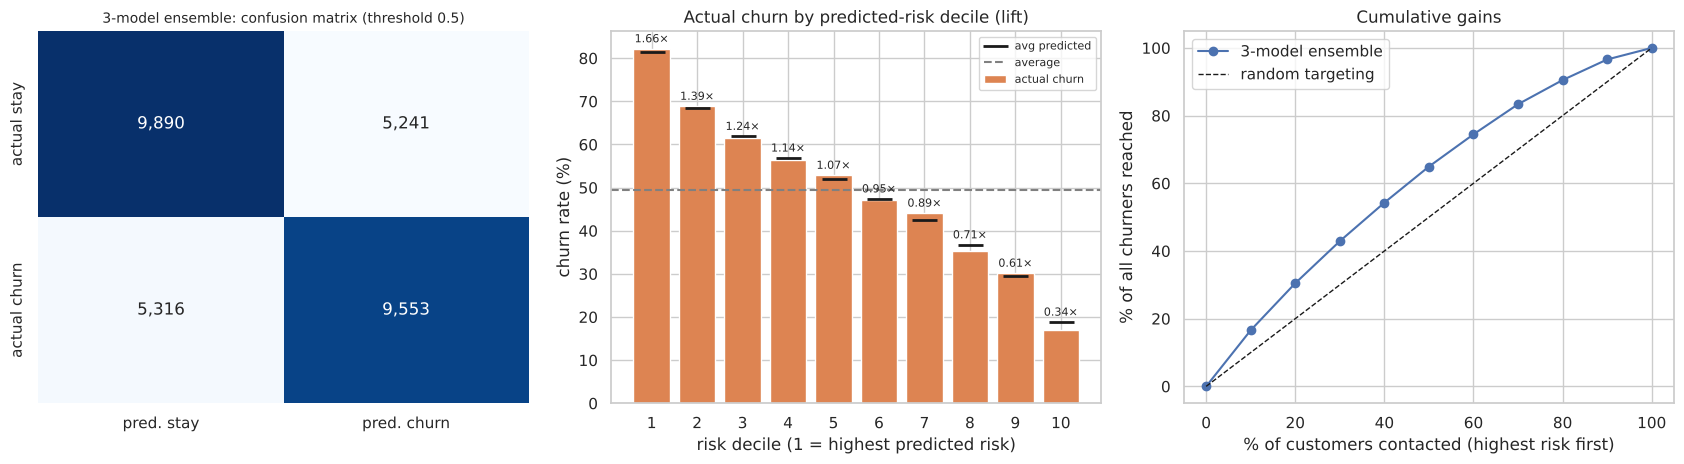

,mean,sum,size,avg predicted,lift,cum % churners caught
decile,,,,,,
1,0.822,2466,3000,0.814,1.658,16.585
2,0.689,2066,3000,0.685,1.389,30.480
3,0.616,1848,3000,0.619,1.243,42.908
4,0.564,1691,3000,0.569,1.137,54.281
5,0.529,1586,3000,0.521,1.067,64.947
6,0.472,1416,3000,0.474,0.952,74.470
7,0.441,1323,3000,0.425,0.890,83.368
8,0.354,1061,3000,0.367,0.714,90.504
9,0.302,905,3000,0.296,0.609,96.590


In [21]:
yhat = (p_best >= 0.5).astype(int)
cm = confusion_matrix(y_test, yhat)
eval_df = pd.DataFrame({"y": y_test.values, "p": p_best})
eval_df["decile"] = pd.qcut(eval_df.p.rank(method="first", ascending=False), 10, labels=range(1, 11))
lift = eval_df.groupby("decile", observed=True).y.agg(["mean", "sum", "size"])
lift["avg predicted"] = eval_df.groupby("decile", observed=True).p.mean()   # calibration check
lift["lift"] = lift["mean"] / eval_df.y.mean()
lift["cum % churners caught"] = lift["sum"].cumsum() / eval_df.y.sum() * 100

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["pred. stay", "pred. churn"], yticklabels=["actual stay", "actual churn"])
axes[0].set_title(f"{BEST}: confusion matrix (threshold 0.5)", fontsize=10)
axes[1].bar(lift.index.astype(int), lift["mean"] * 100, color=PALETTE["churned"], label="actual churn")
axes[1].plot(lift.index.astype(int), lift["avg predicted"] * 100, "k_", ms=18, mew=2, label="avg predicted")
axes[1].axhline(eval_df.y.mean() * 100, ls="--", color="grey", label="average")
for i, (r, pr, l) in enumerate(zip(lift["mean"], lift["avg predicted"], lift["lift"])):
    axes[1].text(i + 1, max(r, pr) * 100 + 1.5, f"{l:.2f}×", ha="center", fontsize=8)
axes[1].set_xticks(range(1, 11))
axes[1].set_xlabel("risk decile (1 = highest predicted risk)"); axes[1].set_ylabel("churn rate (%)")
axes[1].set_title("Actual churn by predicted-risk decile (lift)"); axes[1].legend(fontsize=8)
axes[2].plot([0] + list(range(10, 101, 10)), [0] + list(lift["cum % churners caught"]), marker="o", label=BEST)
axes[2].plot([0, 100], [0, 100], "k--", lw=1, label="random targeting")
axes[2].set_xlabel("% of customers contacted (highest risk first)"); axes[2].set_ylabel("% of all churners reached")
axes[2].set_title("Cumulative gains"); axes[2].legend()
plt.tight_layout(); plt.show()
lift.round(3)

**Reading:** the top-risk decile churns at a much higher rate than the bottom decile; contacting the top 30% of customers reaches a substantially larger share of all churners than random contact. The average predicted probability in each decile is close to the actual churn rate, so the scores are **well calibrated** — which matters because the business case in Section 9 uses the probabilities themselves, not just the ranking. This ranking power is what turns the model into money.

### 8.2 What drives the prediction? (permutation importance)
Permutation importance [10] measures how much test AUC drops when one feature's values are shuffled — i.e. how much the model *relies* on it. It is model-agnostic (it works for the ensemble as a whole) and computed on unseen data.

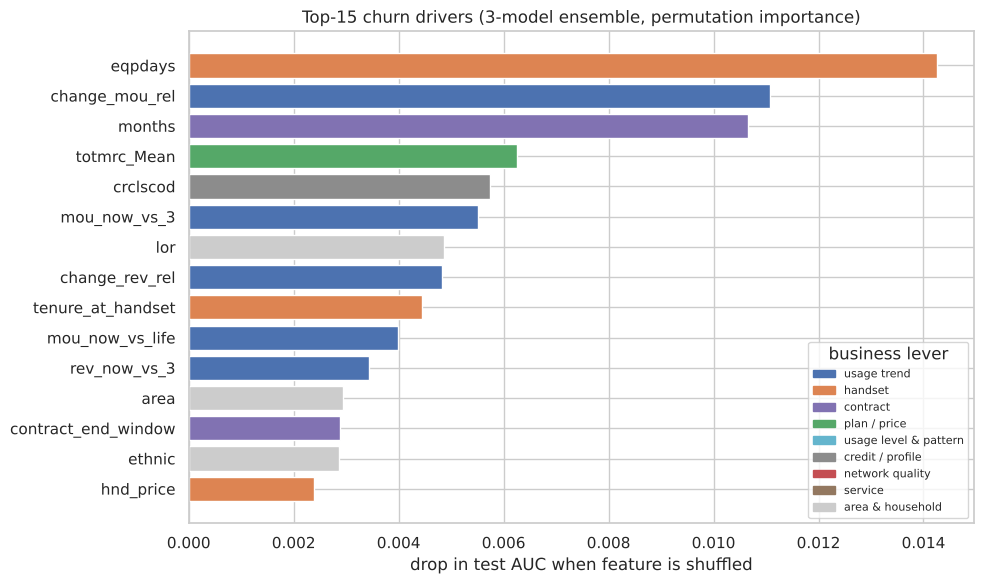

Importance share by business lever (%):
 usage trend              27.9
handset                  20.9
area & household         13.2
contract                 12.7
plan / price              9.0
usage level & pattern     8.4
credit / profile          4.9
network quality           2.2
service                   0.9

Top-15 features:
                     importance             lever
eqpdays                  0.0142           handset
change_mou_rel           0.0111       usage trend
months                   0.0107          contract
totmrc_Mean              0.0063      plan / price
crclscod                 0.0057  credit / profile
mou_now_vs_3             0.0055       usage trend
lor                      0.0049  area & household
change_rev_rel           0.0048       usage trend
tenure_at_handset        0.0044           handset
mou_now_vs_life          0.0040       usage trend
rev_now_vs_3             0.0034       usage trend
area                     0.0029  area & household
contract_end_window  

In [22]:
X_pi = X_test.sample(6000, random_state=SEED)
t0 = time.time()
pi = permutation_importance(best_model, X_pi, y_test.loc[X_pi.index], scoring="roc_auc", n_repeats=4, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X_pi.columns).sort_values(ascending=False)
LEVER = {
    # handset
    **{f: "handset" for f in ["eqpdays", "eqp_to_tenure", "eqp_over_1y", "eqp_over_2y", "hnd_price", "hnd_webcap", "refurb_new",
                              "phones_per_year", "models", "phones", "dualband", "tenure_at_handset", "hnd_price_to_mrc"]},
    # contract timing
    **{f: "contract" for f in ["months", "contract_end_window", "months_mod12"]},
    # usage trend (change vs. the customer's own history)
    **{f: "usage trend" for f in ["change_mou", "change_rev", "mou_trend_3v6", "mou_trend_3vlife", "rev_trend_3vlife",
                                  "qty_trend_3vlife", "mou_now_vs_life", "mou_now_vs_3", "rev_now_vs_3",
                                  "change_mou_rel", "change_rev_rel"]},
    # plan / price
    **{f: "plan / price" for f in ["totmrc_Mean", "mrc_share", "rev_per_min", "overage_share", "ovrrev_Mean", "ovrmou_Mean",
                                   "vceovr_Mean", "datovr_Mean", "asl_flag", "var_rev", "ovr_mou_share", "mou_per_mrc",
                                   "rev_3_vs_mrc"]},
    # usage level & calling pattern (how much / how the customer calls)
    **{f: "usage level & pattern" for f in ["rev_Mean", "mou_Mean", "da_Mean", "roam_Mean", "unan_vce_Mean", "unan_dat_Mean",
                                            "plcd_vce_Mean", "plcd_dat_Mean", "recv_vce_Mean", "recv_sms_Mean", "comp_vce_Mean",
                                            "comp_dat_Mean", "inonemin_Mean", "threeway_Mean", "mou_cvce_Mean", "mou_cdat_Mean",
                                            "mou_rvce_Mean", "owylis_vce_Mean", "mouowylisv_Mean", "iwylis_vce_Mean",
                                            "mouiwylisv_Mean", "peak_vce_Mean", "peak_dat_Mean", "mou_peav_Mean",
                                            "mou_pead_Mean", "opk_vce_Mean", "opk_dat_Mean", "mou_opkv_Mean", "mou_opkd_Mean",
                                            "attempt_Mean", "complete_Mean", "callfwdv_Mean", "callwait_Mean", "totcalls",
                                            "totmou", "totrev", "adjrev", "adjmou", "adjqty", "avgrev", "avgmou", "avgqty",
                                            "avg3mou", "avg3qty", "avg3rev", "avg6mou", "avg6qty", "avg6rev", "recv_to_plcd",
                                            "avg_call_len", "peak_share", "w2w_share", "short_in_share", "unanswered_rate"]},
    # credit
    **{f: "credit / profile" for f in ["crclscod"]},
    # network quality
    **{f: "network quality" for f in ["drop_rate", "fail_rate", "block_rate", "complete_rate", "drop_vce_Mean", "drop_dat_Mean",
                                      "blck_vce_Mean", "blck_dat_Mean", "drop_blk_Mean"]},
    # service
    **{f: "service" for f in ["custcare_per_100", "custcare_Mean", "ccrndmou_Mean", "cc_mou_Mean"]},
}
lever_of = lambda f: LEVER.get(f, "area & household")
top = imp.head(15)
colors = {"usage trend": "#4C72B0", "handset": "#DD8452", "contract": "#8172B2", "plan / price": "#55A868",
          "usage level & pattern": "#64B5CD", "credit / profile": "#8C8C8C", "network quality": "#C44E52",
          "service": "#937860", "area & household": "#CCCCCC"}
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top.index[::-1], top.values[::-1], color=[colors[lever_of(f)] for f in top.index[::-1]])
handles = [plt.Rectangle((0, 0), 1, 1, color=v) for v in colors.values()]
ax.legend(handles, colors.keys(), title="business lever", loc="lower right", fontsize=8)
ax.set_xlabel("drop in test AUC when feature is shuffled"); ax.set_title(f"Top-15 churn drivers ({BEST}, permutation importance)")
plt.tight_layout(); plt.show()
lever_imp = imp.clip(lower=0).groupby(lever_of).sum().sort_values(ascending=False)
lever_share = lever_imp / lever_imp.sum() * 100
print("Importance share by business lever (%):\n", lever_share.round(1).to_string())
print("\nTop-15 features:")
print(pd.DataFrame({"importance": top.round(4), "lever": [lever_of(f) for f in top.index]}).to_string())
print(f"({time.time()-t0:.0f}s)")

### 8.3 Direction of the main effects (partial dependence)

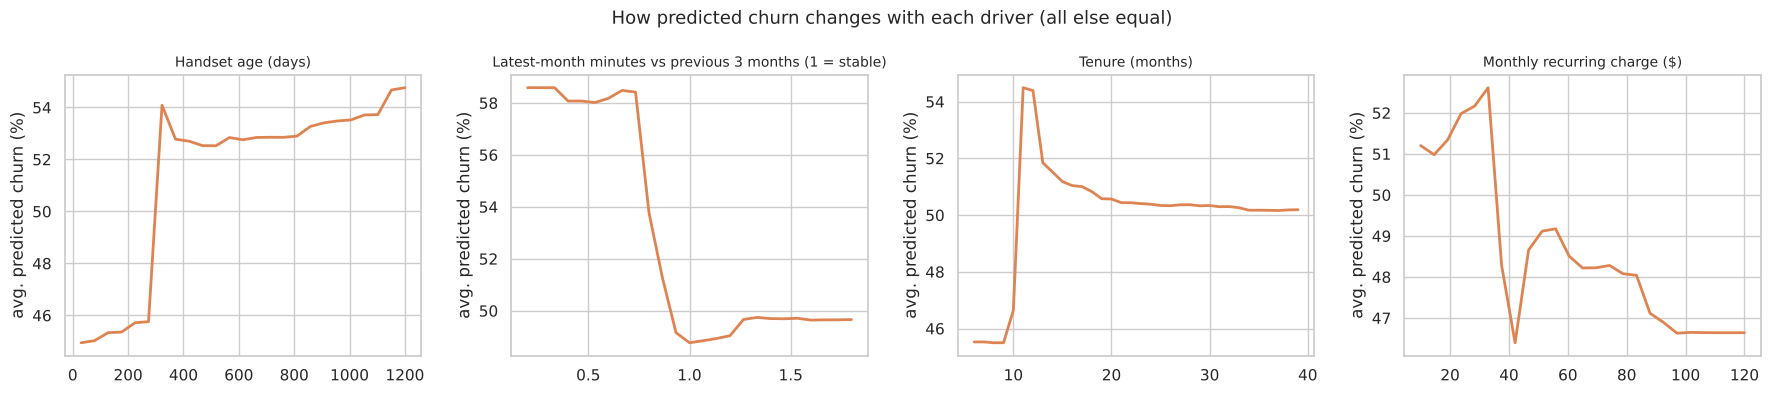

In [23]:
def pdp(model, X, col, grid):
    out = []
    Xs = X.sample(3000, random_state=SEED).copy()
    for v in grid:
        Xs[col] = v
        out.append(model.predict_proba(Xs)[:, 1].mean())
    return np.array(out)

pd_cols = {"eqpdays": np.linspace(30, 1200, 25), "mou_now_vs_3": np.linspace(0.2, 1.8, 25),
           "months": np.arange(6, 40), "totmrc_Mean": np.linspace(10, 120, 25)}
titles = {"eqpdays": "Handset age (days)", "mou_now_vs_3": "Latest-month minutes vs previous 3 months (1 = stable)",
          "months": "Tenure (months)", "totmrc_Mean": "Monthly recurring charge ($)"}
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (col, grid) in zip(axes, pd_cols.items()):
    ax.plot(grid, pdp(best_model, X_test, col, grid) * 100, color=PALETTE["churned"], lw=2)
    ax.set_title(titles[col], fontsize=10); ax.set_ylabel("avg. predicted churn (%)")
plt.suptitle("How predicted churn changes with each driver (all else equal)", fontsize=13)
plt.tight_layout(); plt.show()

**Reading — the model confirms and quantifies the EDA hypotheses:**
- **Usage trend:** the strongest lever (28% of the model's predictive power). Customers whose latest-month usage has fallen below their own previous three months are at markedly higher risk → **early-warning trigger**.
- **Handset age:** predicted risk rises sharply after ~1 year of equipment age → **handset-upgrade lever**.
- **Tenure:** risk peaks around the 11–13-month contract-end window → **timing lever**.
- **Recurring charge:** low-commitment plans are riskier → **plan migration / loyalty bundle lever**.

These are all things Company A can *act on* (together ≈70% of the predictive power); demographics (which cannot be changed) contribute little.

---
## 9. Business Proposal: Risk-Targeted Retention Programme

**Proposal:** every month, score all customers with the model, take the highest-risk group and give each one an offer that fits **why** they are at risk:

| Segment (within high-risk group) | Rule | Offer |
|---|---|---|
| **A. Upgrade-due** | handset age > 365 days | discounted handset upgrade tied to a 12-month renewal |
| **B. Usage-decline** | recent minutes < 70% of lifetime average | proactive call: right-size the plan / loyalty discount |
| **C. Contract-end** | tenure 10–13 months | early renewal bonus |
| **D. Other high-risk** | — | generic loyalty credit |

### 9.1 Segment sizes inside the high-risk group

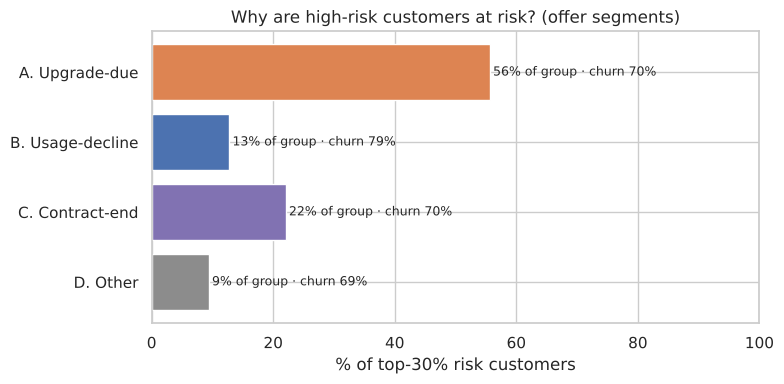

,customers,actual_churn,avg_rev,share
segment,,,,
A. Upgrade-due,5011,69.7%,$50.4,55.7%
B. Usage-decline,1152,78.7%,$40.8,12.8%
C. Contract-end,1988,70.3%,$68.2,22.1%
D. Other,849,68.8%,$84.2,9.4%


In [24]:
test_view = df.loc[X_test.index, ["Customer_ID", "rev_Mean", "eqpdays", "months", "avg3mou", "avgmou"]].copy()
test_view["p"] = p_best
test_view["y"] = y_test.values
def segment(r):
    if r.eqpdays > 365: return "A. Upgrade-due"
    if r.avgmou > 0 and r.avg3mou / r.avgmou < 0.7: return "B. Usage-decline"
    if 10 <= r.months <= 13: return "C. Contract-end"
    return "D. Other"
test_view["segment"] = test_view.apply(segment, axis=1)
hi = test_view[test_view.p >= test_view.p.quantile(0.7)]   # top 30% risk
seg = hi.groupby("segment").agg(customers=("y", "size"), actual_churn=("y", "mean"), avg_rev=("rev_Mean", "mean"))
seg["share"] = seg.customers / seg.customers.sum()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(seg.index[::-1], seg.share[::-1] * 100, color=["#8C8C8C", "#8172B2", "#4C72B0", "#DD8452"])
for i, (s, c) in enumerate(zip(seg.share[::-1], seg.actual_churn[::-1])):
    ax.text(s * 100 + 0.5, i, f"{s:.0%} of group · churn {c:.0%}", va="center", fontsize=9)
ax.set_xlim(0, 100); ax.set_xlabel("% of top-30% risk customers")
ax.set_title("Why are high-risk customers at risk? (offer segments)")
plt.tight_layout(); plt.show()
seg.style.format({"actual_churn": "{:.1%}", "avg_rev": "${:.1f}", "share": "{:.1%}"})

### 9.2 Quantifying the impact — realistic economics

The model is evaluated on the 30,000 held-out customers and scaled to the full 100,000 base. **Important correction:** the dataset is balanced 50/50 by design, but a real operator loses roughly **2% of customers per month** (typical 1.5–3% monthly churn for post-paid wireless). We therefore
1. **re-weight** churners and stayers so the base churn is `BASE_CHURN`, and
2. **re-calibrate** the model's probabilities to that base rate with the standard prior-correction formula: odds_real = odds_model × [b/(1−b)] / [π/(1−π)], where π is the training churn rate and b is the real one.

For each contacted customer:
- if they **would have churned**: with probability `SAVE_RATE` the offer keeps them → we keep `rev_Mean × MARGIN × RETAIN_MONTHS` and pay the `INCENTIVE`;
- if they **would have stayed**: with probability `TAKE_RATE` they still redeem the offer → wasted `INCENTIVE`;
- every contact costs `CONTACT_COST`.

**Offer design that keeps costs down:** the incentive (handset discount / bill credit) is paid **only if the customer signs a 12-month renewal**, and contact goes through low-cost digital channels (SMS, app push, IVR) first.

,value
BASE_CHURN,0.02
SAVE_RATE,0.25
TAKE_RATE,0.15
INCENTIVE,25.00
CONTACT_COST,1.00
MARGIN,0.40
RETAIN_MONTHS,12.00
BASE_SIZE,100000.00


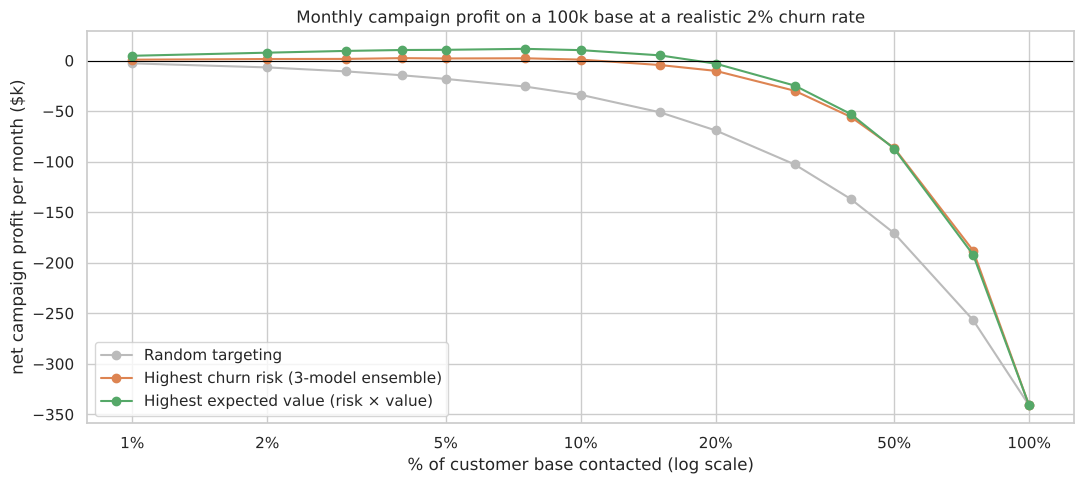

In [25]:
ASSUMPTIONS = dict(
    BASE_CHURN=0.02,       # realistic churn in a 30-day window (post-paid wireless: ~1.5–3%/month)
    SAVE_RATE=0.25,        # share of would-be churners kept by the offer (to be measured in the pilot)
    TAKE_RATE=0.15,        # share of would-be stayers who also redeem (only those willing to sign a renewal)
    INCENTIVE=25.0,        # $ cost of the offer when redeemed (conditional on 12-month renewal)
    CONTACT_COST=1.0,      # $ per contacted customer (SMS / app push / IVR)
    MARGIN=0.40,           # contribution margin on revenue
    RETAIN_MONTHS=12,      # extra months a saved customer stays (= renewal length)
    BASE_SIZE=100_000,
)
display(pd.Series(ASSUMPTIONS, name="value").to_frame())

PI_TRAIN = y_train.mean()
def recalibrate(p, base):
    odds = p / (1 - p) * (base / (1 - base)) / (PI_TRAIN / (1 - PI_TRAIN))
    return odds / (1 + odds)

rev_test = np.nan_to_num(test_view.rev_Mean.values, nan=0.0).clip(min=0)   # unknown revenue -> conservatively $0
y_arr = y_test.values

def expected_net(p, rev, A):
    # expected profit of contacting a customer, computed BEFORE knowing the outcome
    q = recalibrate(p, A["BASE_CHURN"])
    clv = rev * A["MARGIN"] * A["RETAIN_MONTHS"]
    return q * A["SAVE_RATE"] * (clv - A["INCENTIVE"]) - (1 - q) * A["TAKE_RATE"] * A["INCENTIVE"] - A["CONTACT_COST"]

def evaluate(sel, y, rev, A):
    # realised result on the test set, using the true outcomes; re-weighted and scaled to the full base
    w1 = A["BASE_CHURN"] / y.mean(); w0 = (1 - A["BASE_CHURN"]) / (1 - y.mean())
    w = np.where(y == 1, w1, w0) * A["BASE_SIZE"] / len(y)
    ch = sel & (y == 1); st = sel & (y == 0)
    clv = rev * A["MARGIN"] * A["RETAIN_MONTHS"]
    benefit = w * ch * A["SAVE_RATE"] * clv
    cost = w * (ch * A["SAVE_RATE"] * A["INCENTIVE"] + st * A["TAKE_RATE"] * A["INCENTIVE"] + sel * A["CONTACT_COST"])
    return dict(contacted=(w * sel).sum(), churners_reached=(w * ch).sum(), saved=(w * ch).sum() * A["SAVE_RATE"],
                revenue_protected=(w * ch * A["SAVE_RATE"] * rev * A["RETAIN_MONTHS"]).sum(),
                margin_protected=benefit.sum(), cost=cost.sum(), profit=benefit.sum() - cost.sum())

def top_frac(scores, frac):
    k = int(round(frac * len(scores))); sel = np.zeros(len(scores), bool); sel[np.argsort(-scores)[:k]] = True; return sel

rng = np.random.default_rng(SEED)
rand_scores = rng.random(len(y_arr))
ev_scores = expected_net(p_best, rev_test, ASSUMPTIONS)

fracs = np.array([0.01, 0.02, 0.03, 0.04, 0.05, 0.075, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50, 0.75, 1.0])
policies = {"Random targeting": rand_scores, f"Highest churn risk ({BEST})": p_best, "Highest expected value (risk × value)": ev_scores}
curves = {name: pd.DataFrame([evaluate(top_frac(s, f), y_arr, rev_test, ASSUMPTIONS) for f in fracs], index=fracs)
          for name, s in policies.items()}

fig, ax = plt.subplots(figsize=(11, 5))
for (name, c), col in zip(curves.items(), ["#BBBBBB", "#DD8452", "#55A868"]):
    ax.plot(c.index * 100, c.profit / 1e3, marker="o", label=name, color=col)
ax.axhline(0, color="black", lw=0.8)
ax.set_xscale("log"); ax.set_xticks([1, 2, 5, 10, 20, 50, 100]); ax.set_xticklabels(["1%", "2%", "5%", "10%", "20%", "50%", "100%"])
ax.set_xlabel("% of customer base contacted (log scale)"); ax.set_ylabel("net campaign profit per month ($k)")
ax.set_title("Monthly campaign profit on a 100k base at a realistic 2% churn rate")
ax.legend(); plt.tight_layout(); plt.show()

**Reading — the key commercial insight of this PoC:** at a realistic 2% monthly churn rate, **broad retention campaigns destroy value** — most contacted customers would have stayed anyway, so the incentive is wasted on them. Profit only appears when the campaign is **narrow** and when targeting combines **risk *and* customer value**: the very highest-risk customers are often low-revenue accounts that are not worth saving. The model's job is therefore not "find churners" but "find the churners worth saving".

### 9.3 Recommended policy: contact every customer whose expected profit is positive
Instead of picking an arbitrary "top X%", the decision rule is: **contact a customer if expected profit > 0** (expected saved margin > expected offer + contact cost). This is computed *before* the outcome is known, so it can be run in production every month.

,contacted,churners_reached,saved,revenue_protected,margin_protected,cost,profit,ROI (profit / cost),annual profit
Expected-value rule (recommended),"3,550",208,52,"$71,229","$28,492","$17,385","$11,107",0.64,"$133,280"
"Highest risk, same size (6.9%)","2,212",237,59,"$33,179","$13,272","$11,100","$2,172",0.20,"$26,067"
"Random, same size (6.9%)","7,001",135,34,"$23,676","$9,470","$33,591","$-24,120",-0.72,"$-289,442"
Blanket offer to everyone,"100,000","2,000",500,"$347,064","$138,826","$480,000","$-341,174",-0.71,"$-4,094,091"


Recommended campaign: contact 3,550 customers/month (6.9% of base), save ~52 customers/month, protect $0.85M revenue/yr, net profit +$0.13M/yr, ROI 0.64.
Blanket offer to everyone: net profit −$4.09M/yr.


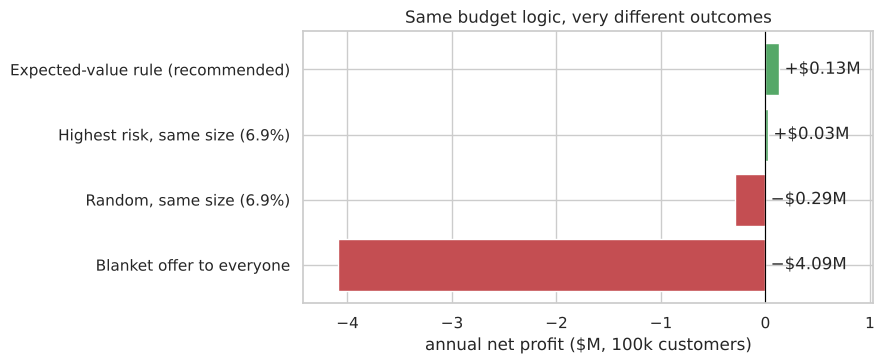

In [26]:
sel_ev = ev_scores > 0
frac_ev = sel_ev.mean()
res = {
    "Expected-value rule (recommended)": evaluate(sel_ev, y_arr, rev_test, ASSUMPTIONS),
    f"Highest risk, same size ({frac_ev:.1%})": evaluate(top_frac(p_best, frac_ev), y_arr, rev_test, ASSUMPTIONS),
    f"Random, same size ({frac_ev:.1%})": evaluate(top_frac(rand_scores, frac_ev), y_arr, rev_test, ASSUMPTIONS),
    "Blanket offer to everyone": evaluate(np.ones(len(y_arr), bool), y_arr, rev_test, ASSUMPTIONS),
}
impact = pd.DataFrame(res).T
impact["ROI (profit / cost)"] = impact.profit / impact.cost
impact["annual profit"] = impact.profit * 12
fmt = {c: "{:,.0f}" for c in ["contacted", "churners_reached", "saved"]}
fmt.update({c: "${:,.0f}" for c in ["revenue_protected", "margin_protected", "cost", "profit", "annual profit"]})
fmt["ROI (profit / cost)"] = "{:.2f}"
display(impact.style.format(fmt))

r = impact.iloc[0]
money = lambda v: f"{'−' if v < 0 else '+'}${abs(v):,.2f}M"
print(f"Recommended campaign: contact {r.contacted:,.0f} customers/month ({frac_ev:.1%} of base), "
      f"save ~{r.saved:,.0f} customers/month, protect ${r.revenue_protected*12/1e6:,.2f}M revenue/yr, "
      f"net profit {money(r.profit*12/1e6)}/yr, ROI {r['ROI (profit / cost)']:.2f}.")
print(f"Blanket offer to everyone: net profit {money(impact.iloc[3].profit*12/1e6)}/yr.")

fig, ax = plt.subplots(figsize=(9, 3.8))
vals = impact["annual profit"] / 1e6
ax.barh(vals.index[::-1], vals.values[::-1], color=["#C44E52" if v < 0 else "#55A868" for v in vals.values[::-1]])
for i, v in enumerate(vals.values[::-1]):
    ax.text(max(v, 0) + 0.05, i, money(v), va="center", ha="left")   # labels right of zero: never hide the axis labels
ax.set_xlim(vals.min() * 1.08, max(vals.max(), 0) + 0.9)
ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("annual net profit ($M, 100k customers)")
ax.set_title("Same budget logic, very different outcomes")
plt.tight_layout(); plt.show()

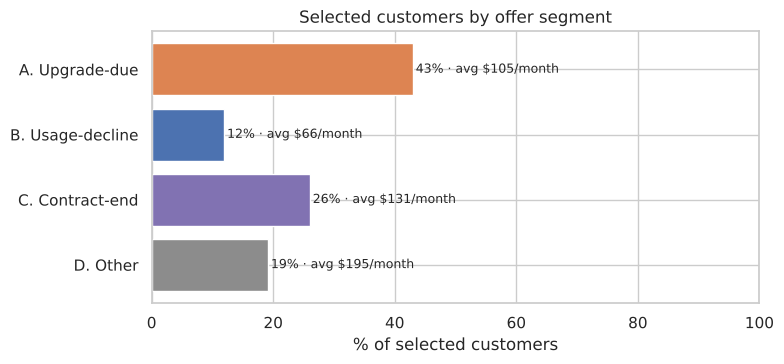

,customers,actual_churn_sample,avg_monthly_rev,avg_risk,share
segment,,,,,
A. Upgrade-due,887,76.9%,$105.4,0.77,43.0%
B. Usage-decline,246,89.8%,$66.0,0.86,11.9%
C. Contract-end,537,70.8%,$131.4,0.74,26.0%
D. Other,395,67.3%,$194.7,0.64,19.1%


,selected (EV rule),top-risk same size,all customers
rev_Mean,124.55,47.71,58.47
p,0.75,0.84,0.50
eqpdays,378.53,466.28,392.53
months,17.42,18.96,18.85


In [27]:
# Who is selected, and which offer do they get?
test_view["exp_net"] = ev_scores
chosen = test_view[sel_ev]
seg = chosen.groupby("segment").agg(customers=("y", "size"), actual_churn_sample=("y", "mean"),
                                    avg_monthly_rev=("rev_Mean", "mean"), avg_risk=("p", "mean"))
seg["share"] = seg.customers / seg.customers.sum()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(seg.index[::-1], seg.share[::-1] * 100, color=["#8C8C8C", "#8172B2", "#4C72B0", "#DD8452"][-len(seg):])
for i, (s, rv) in enumerate(zip(seg.share[::-1], seg.avg_monthly_rev[::-1])):
    ax.text(s * 100 + 0.5, i, f"{s:.0%} · avg ${rv:,.0f}/month", va="center", fontsize=9)
ax.set_xlim(0, 100); ax.set_xlabel("% of selected customers"); ax.set_title("Selected customers by offer segment")
plt.tight_layout(); plt.show()
cmp_val = pd.DataFrame({"selected (EV rule)": chosen[["rev_Mean", "p", "eqpdays", "months"]].mean(),
                        "top-risk same size": test_view[top_frac(p_best, frac_ev)][["rev_Mean", "p", "eqpdays", "months"]].mean(),
                        "all customers": test_view[["rev_Mean", "p", "eqpdays", "months"]].mean()})
display(seg.style.format({"actual_churn_sample": "{:.1%}", "avg_monthly_rev": "${:.1f}", "avg_risk": "{:.2f}", "share": "{:.1%}"}))
cmp_val.round(2)

### 9.4 Sensitivity analysis
Save rate, incentive and the true base churn rate are the most uncertain inputs. Each cell shows the annual net profit of the expected-value rule (re-optimised for that scenario; 0 = the rule contacts nobody, i.e. "don't run the campaign").

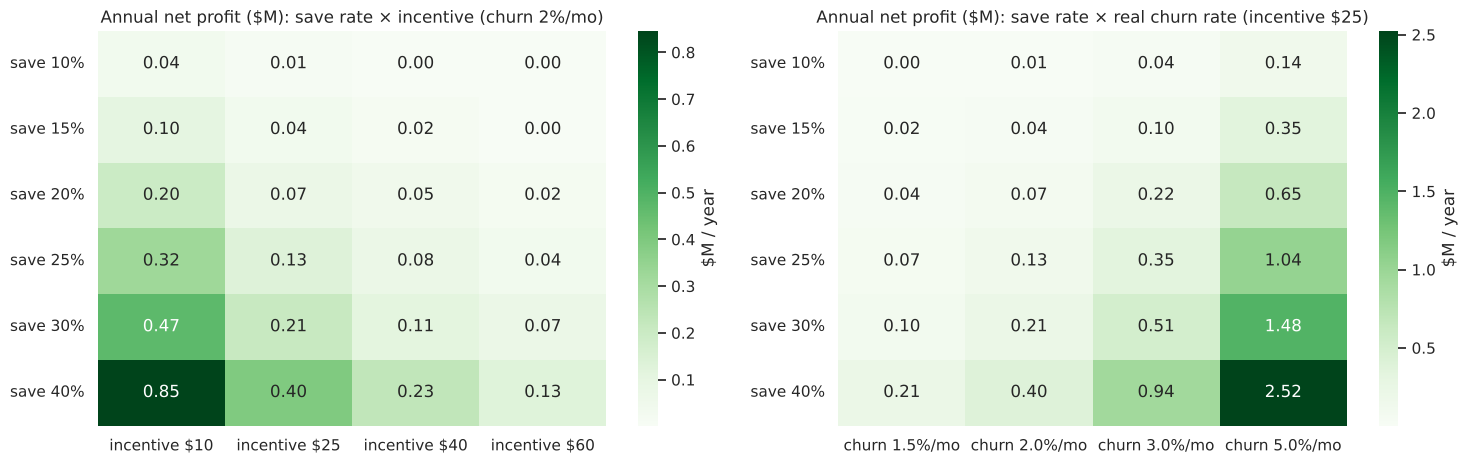

In [28]:
def ev_profit(A):
    s = expected_net(p_best, rev_test, A) > 0
    return evaluate(s, y_arr, rev_test, A)["profit"] * 12 / 1e6

save_rates = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40]
sens1 = pd.DataFrame({f"incentive ${inc}": [ev_profit({**ASSUMPTIONS, "SAVE_RATE": s, "INCENTIVE": inc}) for s in save_rates]
                      for inc in [10, 25, 40, 60]}, index=[f"save {s:.0%}" for s in save_rates])
sens2 = pd.DataFrame({f"churn {b:.1%}/mo": [ev_profit({**ASSUMPTIONS, "SAVE_RATE": s, "BASE_CHURN": b}) for s in save_rates]
                      for b in [0.015, 0.02, 0.03, 0.05]}, index=[f"save {s:.0%}" for s in save_rates])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.heatmap(sens1, annot=True, fmt=".2f", cmap="Greens", ax=axes[0], cbar_kws={"label": "$M / year"})
axes[0].set_title("Annual net profit ($M): save rate × incentive (churn 2%/mo)")
sns.heatmap(sens2, annot=True, fmt=".2f", cmap="Greens", ax=axes[1], cbar_kws={"label": "$M / year"})
axes[1].set_title(r"Annual net profit (\$M): save rate × real churn rate (incentive \$25)")  # \$ = literal dollar
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

**Reading:** because the expected-value rule simply stops contacting customers when an offer is not worth it, it **never loses much money**: in bad scenarios it shrinks the campaign instead of burning budget. Profit grows quickly with a higher save rate, cheaper incentives, or a higher real churn rate (e.g. prepaid-heavy or more competitive markets). That is why the first deliverable after this PoC is a **pilot that measures the real save rate**.

### 9.5 Proposal summary
1. **Deploy a monthly churn-risk score** — ensemble of LightGBM, CatBoost and XGBoost, **test ROC-AUC 0.709, accuracy 0.648** — for every subscriber, re-calibrated to the real churn rate.
2. **Target by expected value, not by risk alone:** contact a customer only if *expected saved margin > expected offer + contact cost*. This selects ~7% of the base (≈3.6k customers/month), skewed towards **higher-value** customers (avg. $125/month vs $48 for a pure top-risk list).
3. **Match the offer to the reason:** upgrade-due handset (≈43% of selected) → discounted upgrade tied to a 12-month renewal; contract-end (≈26%) → early-renewal bonus; usage-decline (≈12%) → plan right-sizing; others (≈19%) → loyalty credit.
4. **Expected impact (base case, 100k customers):** ~52 customers saved/month, **≈$0.85M revenue protected and ≈ +$0.13M net profit per year (ROI 0.64)**, versus **−$4.09M/year** for a blanket offer and **−$0.29M/year** for random targeting of the same size. Impact grows quickly with the real save rate (see sensitivity).
5. **Run a 3-month randomised pilot** to measure the real save rate before scaling.

---
## 10. Risks & Next Steps

**Risks / limitations**
- **Assumption risk:** save rate, incentive cost, margin and the true churn rate are not in the data. → Measure them in a pilot; the sensitivity tables show the decision is robust because the rule shrinks the campaign when offers stop paying back.
- **Sampling:** the 50/50 balance is artificial; probabilities are re-calibrated to the real churn rate (ranking quality / AUC is unaffected).
- **Causality:** the model shows *association*. An old handset predicts churn, but whether an upgrade offer *prevents* it must be proven experimentally.
- **Model drift:** behaviour and competitor offers change; retrain monthly and monitor AUC.
- **Complexity:** the ensemble is harder to explain than a single model. We therefore explain it *as a whole* (permutation importance and partial dependence above are computed on the ensemble), and keep the single LightGBM as a fallback — it is only slightly less accurate.
- **Accuracy ceiling:** part of churn is driven by events that are not in the data (competitor offers, moving house), so even the improved model ranks a leaver above a stayer only ~7 times out of 10; further gains need new data rather than more tuning.
- **Fairness / privacy:** demographic attributes (ethnicity, income) should be excluded from targeting decisions; they contribute little to the model.

**Next steps (PoC → production)**
1. **Pilot (3 months):** randomised controlled test — eligible customers split into *offer* vs *control* groups to measure the true save rate and ROI.
2. **Uplift modelling:** target customers whose churn is most *reducible* by the offer, not just most likely.
3. **Data enrichment:** competitor-offer timing, complaint text, network-cell data — the most promising route to further accuracy gains.
4. **Integration:** monthly scoring job feeding the CRM / call-centre queue.

In [29]:
# Operational deliverable: monthly target list for the whole base (expected-value rule, with offer segment).
# Every customer is scored by a model that never saw their outcome: training customers get their out-of-fold
# score from the 5-fold cross-validation, test customers the score of the final model.
# (In production, the model is refitted on all labelled customers and applied to next month's snapshot.)
all_p = pd.concat([pd.Series(oof[BEST], index=X_train.index), pd.Series(p_best, index=X_test.index)]).reindex(df.index).values
scored = df[["Customer_ID", "rev_Mean", "eqpdays", "months", "avg3mou", "avgmou"]].copy()
scored["churn_risk_model"] = all_p
scored["churn_risk_real"] = recalibrate(all_p, ASSUMPTIONS["BASE_CHURN"])
scored["expected_profit"] = expected_net(all_p, np.nan_to_num(scored.rev_Mean.values, nan=0.0).clip(min=0), ASSUMPTIONS)
scored["segment"] = scored.apply(segment, axis=1)
target_list = scored[scored.expected_profit > 0].sort_values("expected_profit", ascending=False)
print(f"Target list: {len(target_list):,} customers ({len(target_list)/len(scored):.1%} of base)")
print(target_list.segment.value_counts().to_string())
target_list[["Customer_ID", "churn_risk_real", "rev_Mean", "expected_profit", "segment"]].head(10).round(3)

Target list: 6,808 customers (6.8% of base)
segment
A. Upgrade-due      2970
C. Contract-end     1817
D. Other            1265
B. Usage-decline     756


,Customer_ID,churn_risk_real,rev_Mean,expected_profit,segment
39170,1039171,0.017,3843.262,71.851,D. Other
48682,1048683,0.090,576.855,57.456,A. Upgrade-due
90195,1090196,0.176,278.357,53.554,C. Contract-end
47315,1047316,0.038,1223.380,50.788,A. Upgrade-due
45847,1045848,0.067,632.875,46.139,D. Other
90549,1090550,0.063,598.978,40.635,C. Contract-end
34759,1034760,0.097,387.778,40.122,D. Other
61970,1061971,0.043,758.170,34.645,C. Contract-end
37052,1037053,0.185,175.950,33.926,A. Upgrade-due
68058,1068059,0.071,450.085,33.339,D. Other


---
## 11. References

1. Reichheld, F. F., & Schefter, P. (2000). *E-Loyalty: Your Secret Weapon on the Web.* Harvard Business Review, 78(4), 105–113. https://hbr.org/2000/07/e-loyalty-your-secret-weapon-on-the-web
2. Gallo, A. (2014, October 29). *The Value of Keeping the Right Customers.* Harvard Business Review. https://hbr.org/2014/10/the-value-of-keeping-the-right-customers
3. GSMA Intelligence (2024). *The Mobile Economy 2024.* https://www.gsma.com/solutions-and-impact/connectivity-for-good/mobile-economy/
4. Ericsson (2024). *Ericsson Mobility Report.* https://www.ericsson.com/en/reports-and-papers/mobility-report
5. Verbeke, W., Dejaeger, K., Martens, D., Hur, J., & Baesens, B. (2012). New insights into churn prediction in the telecommunication sector: A profit driven data mining approach. *European Journal of Operational Research*, 218(1), 211–229. https://doi.org/10.1016/j.ejor.2011.09.031
6. Neslin, S. A., Gupta, S., Kamakura, W., Lu, J., & Mason, C. H. (2006). Defection detection: Measuring and understanding the predictive accuracy of customer churn models. *Journal of Marketing Research*, 43(2), 204–211. https://doi.org/10.1509/jmkr.43.2.204
7. Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR*, 12, 2825–2830.
8. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *Proc. KDD 2016*, 785–794. https://doi.org/10.1145/2939672.2939785
9. Ke, G., et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 30*.
10. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5–32. (random forest & permutation importance)
11. GCI World 2026 — Final Assignment Tutorial (`tutorial.ipynb`) and Company A Dataset Overview (course materials).
12. Generative-AI assistance (Claude Code) used for drafting, code review and the model-accuracy improvements — chat URLs: https://claude.ai/code/session_01NK6VUjaBPQ9mz2bW8AwXsP and https://claude.ai/code/session_01NK6VUnLRE5S8Gnv2BQTJqH
13. Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V., & Gulin, A. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 31*, 6638–6648.
14. Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *Proc. KDD 2019*, 2623–2631. https://doi.org/10.1145/3292500.3330701
15. Dietterich, T. G. (2000). Ensemble Methods in Machine Learning. *Multiple Classifier Systems (MCS 2000)*, LNCS 1857, 1–15. https://doi.org/10.1007/3-540-45014-9_1

*Market figures should be checked against the latest editions of [3] and [4] before the final slide deck; add local-market sources (regulator statistics for your country) to strengthen Section 1.*